In [200]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

import warnings
warnings.filterwarnings('ignore')

In [201]:
BLUE = '#4472C4'
DARK_BLUE = '#203864'
NAVY = '#14213D'
LIGHT_BLUE = '#8FAADC'
ORANGE = '#ED7D31'
WHITE = '#FFFFFF'

sns.set_theme(style='darkgrid')

plt.rcParams['figure.facecolor'] = NAVY
plt.rcParams['axes.facecolor'] = DARK_BLUE
plt.rcParams['text.color'] = WHITE
plt.rcParams['axes.labelcolor'] = WHITE
plt.rcParams['xtick.color'] = WHITE
plt.rcParams['ytick.color'] = WHITE
plt.rcParams['grid.color'] = '#A6A6A6'

In [202]:
import pandas as pd
df = pd.read_excel(r"C:\Users\mahak\Downloads\ep\DATASET EP.xlsx")
df.head()

,OrderID,OrderDate,CustomerID,CustomerSegment,Gender,Age,City,State,ProductID,ProductName,...,DeliveryDays,ReturnedFlag,CancelledFlag,ReturnReason,RefundAmount,MarketingChannel,Campaign,Rating,DeliveryDelayDays,OnTimeDeliveryFlag
0,O00001,2025-06-14,C0121,Returning Customer,Male,23,Ahmedabad,Gujarat,P011,Study Table,...,4.0,0,0,Not Applicable,0,Paid Search,Republic Day Sale,NaN,0.0,1.0
1,O00002,2025-10-12,C0130,New Customer,Female,38,Hyderabad,Telangana,P009,Mixer Grinder,...,4.0,0,0,Not Applicable,0,Direct,New Year Sale,2.0,1.0,0.0
2,O00003,2025-10-26,C0490,New Customer,Male,27,Ahmedabad,Gujarat,P020,Dumbbell Set,...,3.0,0,0,Not Applicable,0,Email,Republic Day Sale,4.0,-3.0,1.0
3,O00004,2025-01-08,C0301,New Customer,Male,27,Noida,Uttar Pradesh,P020,Dumbbell Set,...,4.0,1,0,Changed Mind,6080,Paid Search,Summer Sale,5.0,0.0,1.0
4,O00005,2025-10-30,C0458,Returning Customer,Female,26,Gurugram,Haryana,P018,Camping Tent,...,7.0,0,0,Not Applicable,0,Affiliate,NaN,3.0,1.0,0.0


In [203]:
df['OrderDate'] = pd.to_datetime(df['OrderDate'])

In [204]:
df.duplicated().sum()

np.int64(0)

In [205]:
df = df.drop_duplicates()

In [206]:
df["NetSales"].sum()

np.float64(10778727.5)

In [207]:
df["Profit"].sum()

np.float64(3475079.71)

In [208]:
df["OrderID"].nunique()

1500

In [209]:
print(df.columns.tolist())

['OrderID', 'OrderDate', 'CustomerID', 'CustomerSegment', 'Gender', 'Age', 'City', 'State', 'ProductID', 'ProductName', 'Category', 'Subcategory', 'Quantity', 'UnitPrice', 'DiscountPct', 'GrossSales', 'DiscountAmount', 'NetSales', 'Cost', 'Profit', 'PaymentMethod', 'OrderStatus', 'ExpectedDeliveryDate', 'DeliveryDate', 'DeliveryDays', 'ReturnedFlag', 'CancelledFlag', 'ReturnReason', 'RefundAmount', 'MarketingChannel', 'Campaign', 'Rating', 'DeliveryDelayDays', 'OnTimeDeliveryFlag']


In [211]:
from matplotlib.ticker import FuncFormatter

CAT_COL  = 'Category'
PROD_COL = 'ProductName'
CREAM = '#F2EFD8'
MONTHS = ['Jan','Feb','Mar','Apr','May','Jun','Jul','Aug','Sep','Oct','Nov','Dec']
plain = FuncFormatter(lambda x, p: f'{int(x)}')

df['Month'] = df['OrderDate'].dt.month

monthly  = df.groupby('Month')['NetSales'].sum().reindex(range(1, 13))
category = df.groupby(CAT_COL)['NetSales'].sum().sort_index()
top10    = df.groupby(PROD_COL)['NetSales'].sum().nlargest(10).sort_values()
segment  = df.groupby('CustomerSegment')['NetSales'].sum()
SEG_COLORS = {'New Customer': BLUE, 'Returning Customer': ORANGE, 'VIP': LIGHT_BLUE}

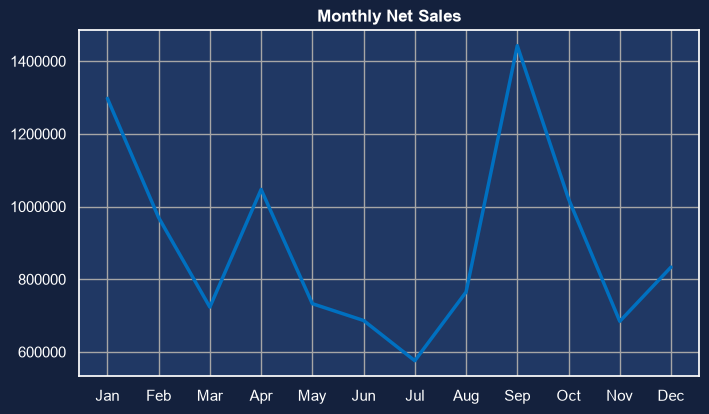

In [213]:
def monthly_chart(ax):
    ax.plot(MONTHS, monthly.values, color='#0070C0', lw=2.5)
    ax.set_title('Monthly Net Sales', fontweight='bold')
    ax.yaxis.set_major_formatter(plain)

fig, ax = plt.subplots(figsize=(8, 4.5), facecolor=NAVY)
monthly_chart(ax)
plt.show()

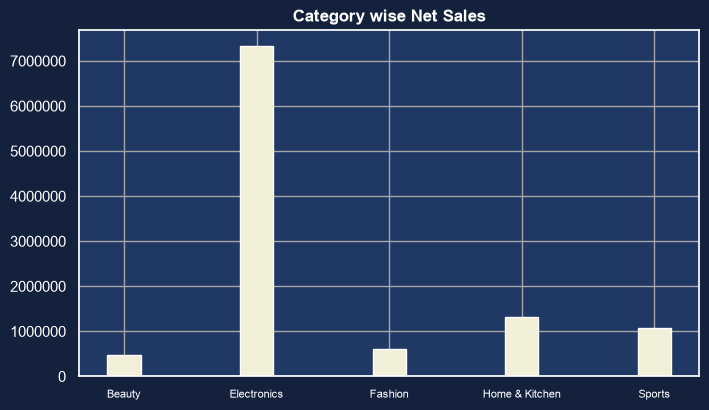

In [214]:
def category_chart(ax):
    ax.bar(category.index, category.values, color=CREAM, width=0.25)
    ax.set_title('Category wise Net Sales', fontweight='bold')
    ax.yaxis.set_major_formatter(plain)
    ax.tick_params(axis='x', labelsize=8)

fig, ax = plt.subplots(figsize=(8, 4.5), facecolor=NAVY)
category_chart(ax)
plt.show()

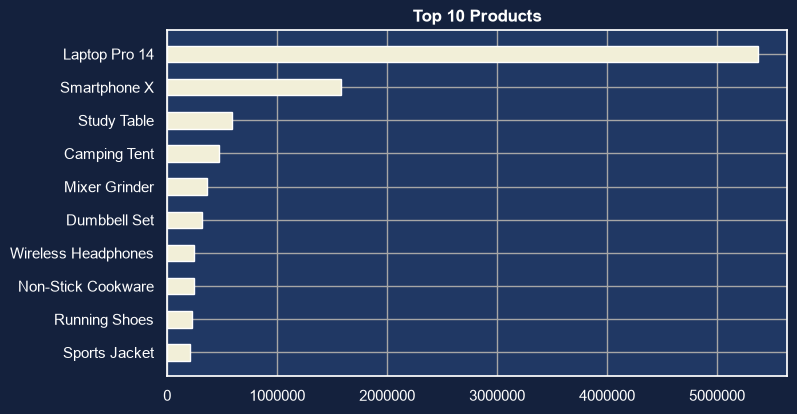

In [215]:
def top10_chart(ax):
    ax.barh(top10.index, top10.values, color=CREAM, height=0.5)
    ax.set_title('Top 10 Products', fontweight='bold')
    ax.xaxis.set_major_formatter(plain)

fig, ax = plt.subplots(figsize=(8, 4.5), facecolor=NAVY)
top10_chart(ax)
plt.show()

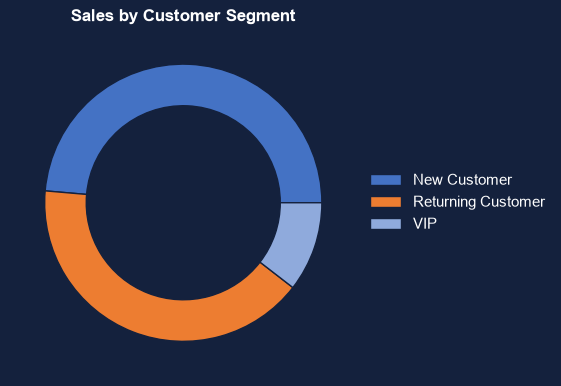

In [216]:
def segment_chart(ax):
    ax.pie(segment.values, colors=[SEG_COLORS[s] for s in segment.index],
           wedgeprops=dict(width=0.3, edgecolor=NAVY))
    ax.legend(segment.index, loc='center left', bbox_to_anchor=(1, 0.5),
              frameon=False, labelcolor=WHITE)
    ax.set_title('Sales by Customer Segment', fontweight='bold')

fig, ax = plt.subplots(figsize=(8, 4.5), facecolor=NAVY)
segment_chart(ax)
plt.show()

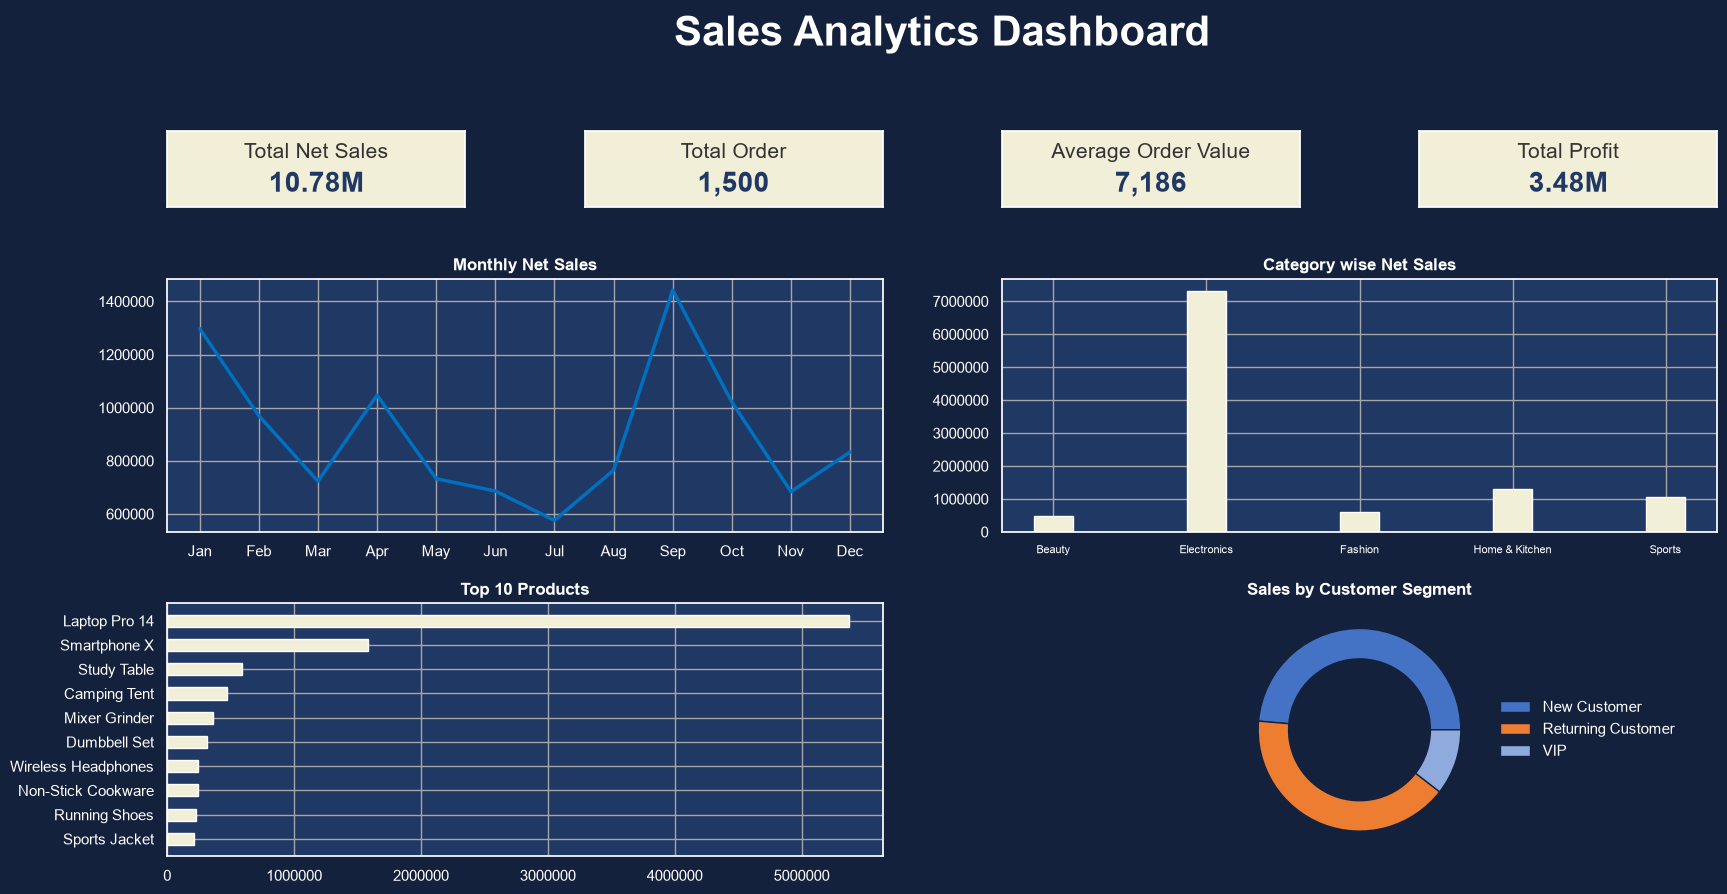

In [217]:
fig = plt.figure(figsize=(20, 11), facecolor=NAVY)
gs = fig.add_gridspec(4, 4, height_ratios=[0.6, 0.9, 3, 3], hspace=0.45, wspace=0.4)

# Title
ax = fig.add_subplot(gs[0, :]); ax.axis('off')
ax.text(0.5, 0.5, 'Sales Analytics Dashboard', ha='center', va='center',
        fontsize=30, fontweight='bold', color=WHITE)

# 4 KPI cards
orders = df['OrderID'].nunique()
kpis = [('Total Net Sales', f"{df['NetSales'].sum()/1e6:.2f}M"),
        ('Total Order', f"{orders:,}"),
        ('Average Order Value', f"{df['NetSales'].sum()/orders:,.0f}"),
        ('Total Profit', f"{df['Profit'].sum()/1e6:.2f}M")]
for i, (label, val) in enumerate(kpis):
    ax = fig.add_subplot(gs[1, i])
    ax.set_facecolor(CREAM); ax.set_xticks([]); ax.set_yticks([])
    ax.grid(False)
    ax.text(0.5, 0.72, label, ha='center', va='center', fontsize=15, color='#333333')
    ax.text(0.5, 0.30, val, ha='center', va='center', fontsize=20,
            fontweight='bold', color=DARK_BLUE)

# 4 charts, 2x2
monthly_chart(fig.add_subplot(gs[2, 0:2]))
category_chart(fig.add_subplot(gs[2, 2:4]))
top10_chart(fig.add_subplot(gs[3, 0:2]))
segment_chart(fig.add_subplot(gs[3, 2:4]))

fig.savefig('Sales_Dashboard.png', dpi=200, facecolor=NAVY, bbox_inches='tight')
plt.show()

In [218]:
from matplotlib.ticker import FuncFormatter

CREAM = '#F2EFD8'
plain = FuncFormatter(lambda x, p: f'{int(x)}')

SEG_COLORS = {'New Customer': BLUE, 'Returning Customer': ORANGE, 'VIP': LIGHT_BLUE}
GEN_COLORS = {'Female': ORANGE, 'Male': BLUE, 'Other': LIGHT_BLUE}

seg_cust   = df.groupby('CustomerSegment')['CustomerID'].nunique()
gen_cust   = df.groupby('Gender')['CustomerID'].nunique()
seg_sales  = df.groupby('CustomerSegment')['NetSales'].sum()
seg_profit = df.groupby('CustomerSegment')['Profit'].sum()

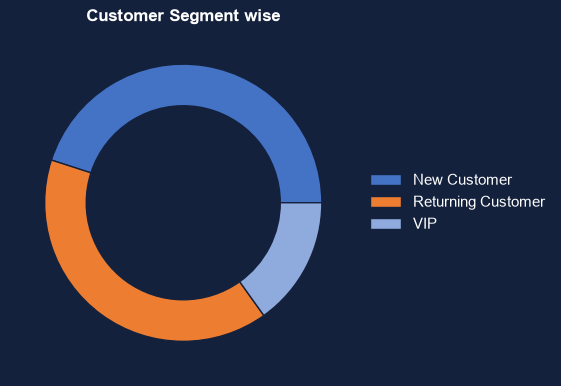

In [219]:
def seg_cust_chart(ax):
    ax.pie(seg_cust.values, colors=[SEG_COLORS[s] for s in seg_cust.index],
           wedgeprops=dict(width=0.3, edgecolor=NAVY))
    ax.legend(seg_cust.index, loc='center left', bbox_to_anchor=(1, 0.5),
              frameon=False, labelcolor=WHITE)
    ax.set_title('Customer Segment wise', fontweight='bold')

fig, ax = plt.subplots(figsize=(8, 4.5), facecolor=NAVY)
seg_cust_chart(ax)
plt.show()

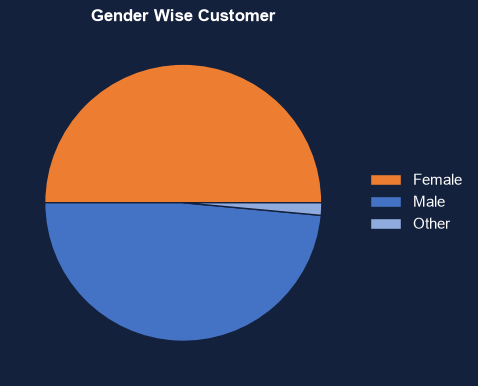

In [220]:
def gender_chart(ax):
    ax.pie(gen_cust.values, colors=[GEN_COLORS[g] for g in gen_cust.index],
           wedgeprops=dict(edgecolor=NAVY))
    ax.legend(gen_cust.index, loc='center left', bbox_to_anchor=(1, 0.5),
              frameon=False, labelcolor=WHITE)
    ax.set_title('Gender Wise Customer', fontweight='bold')

fig, ax = plt.subplots(figsize=(8, 4.5), facecolor=NAVY)
gender_chart(ax)
plt.show()

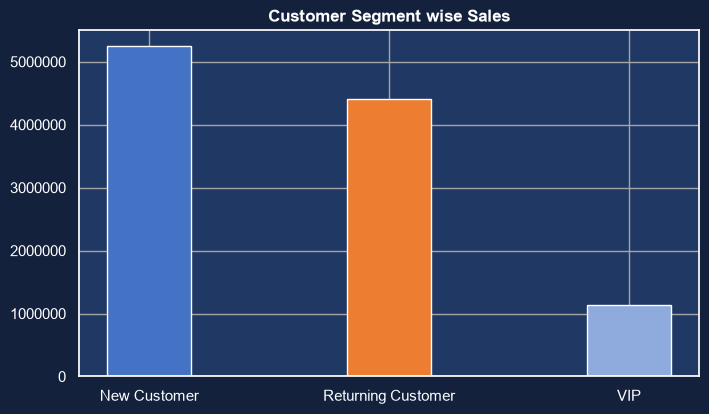

In [221]:
def seg_sales_chart(ax):
    ax.bar(seg_sales.index, seg_sales.values,
           color=[SEG_COLORS[s] for s in seg_sales.index], width=0.35)
    ax.set_title('Customer Segment wise Sales', fontweight='bold')
    ax.yaxis.set_major_formatter(plain)

fig, ax = plt.subplots(figsize=(8, 4.5), facecolor=NAVY)
seg_sales_chart(ax)
plt.show()

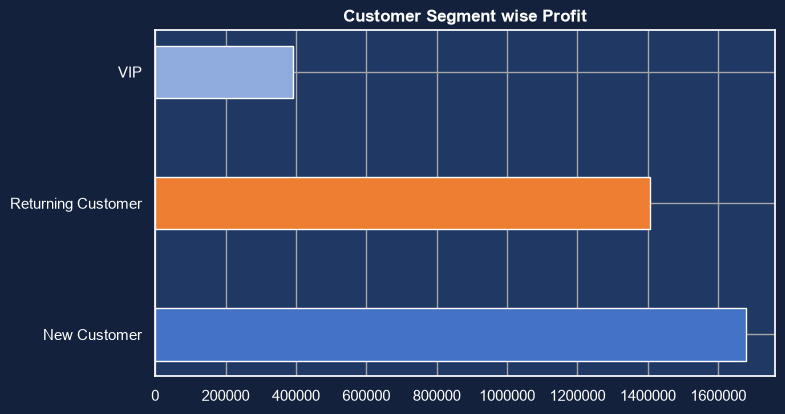

In [222]:
def seg_profit_chart(ax):
    ax.barh(seg_profit.index, seg_profit.values,
            color=[SEG_COLORS[s] for s in seg_profit.index], height=0.4)
    ax.set_title('Customer Segment wise Profit', fontweight='bold')
    ax.xaxis.set_major_formatter(plain)

fig, ax = plt.subplots(figsize=(8, 4.5), facecolor=NAVY)
seg_profit_chart(ax)
plt.show()

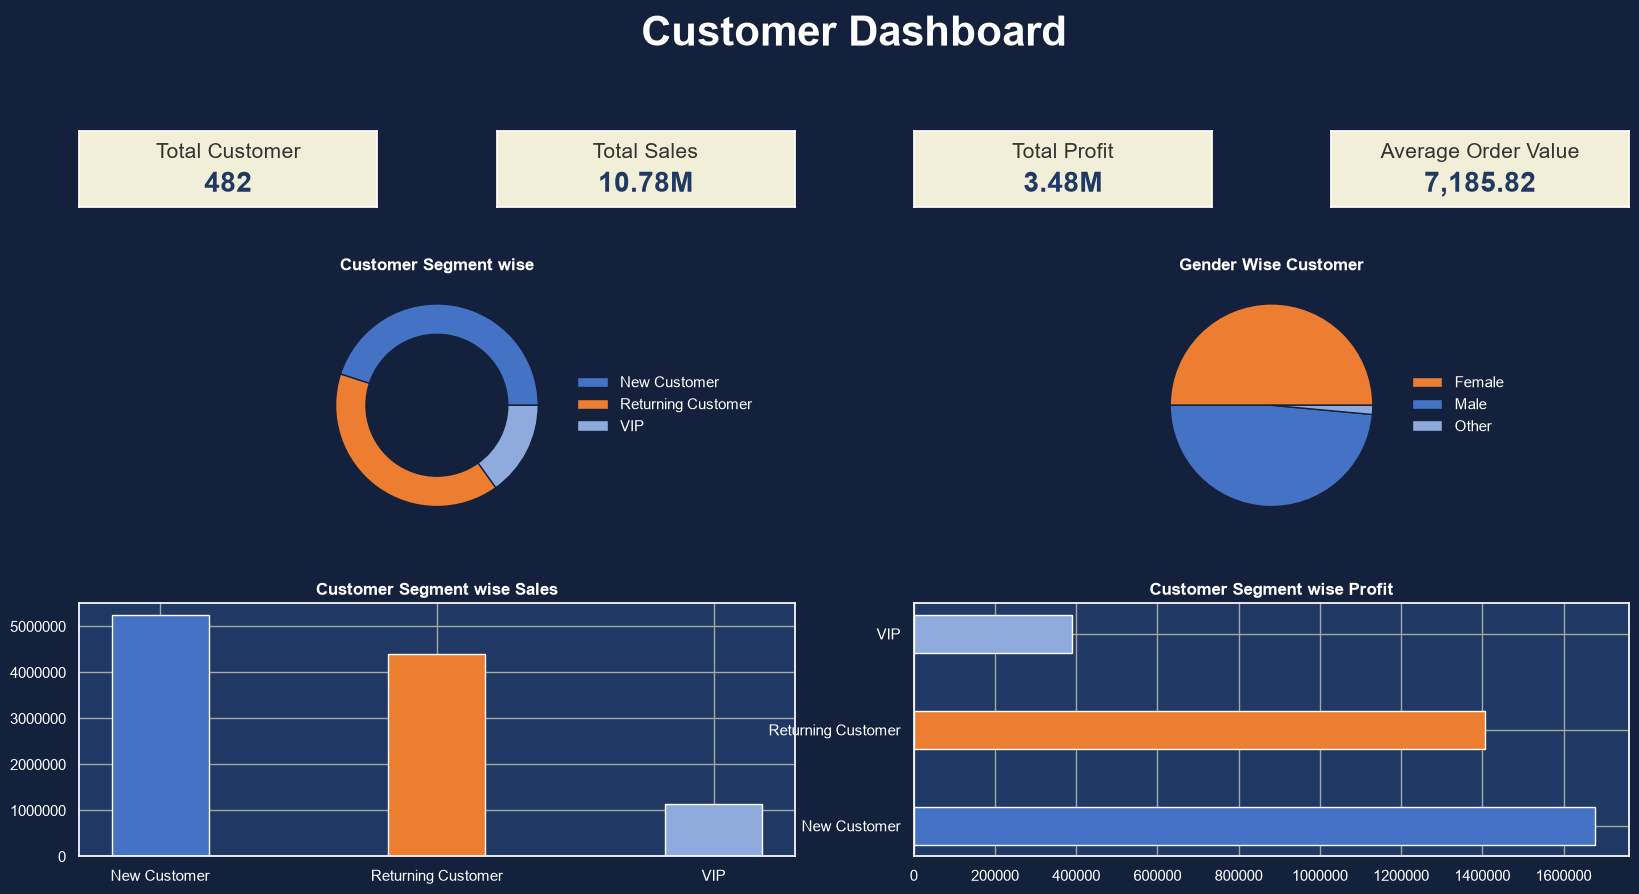

In [223]:
fig = plt.figure(figsize=(20, 11), facecolor=NAVY)
gs = fig.add_gridspec(4, 4, height_ratios=[0.6, 0.9, 3, 3], hspace=0.45, wspace=0.4)

# Title
ax = fig.add_subplot(gs[0, :]); ax.axis('off')
ax.text(0.5, 0.5, 'Customer Dashboard', ha='center', va='center',
        fontsize=30, fontweight='bold', color=WHITE)

# 4 KPI cards
orders = df['OrderID'].nunique()
kpis = [('Total Customer', f"{df['CustomerID'].nunique():,}"),
        ('Total Sales', f"{df['NetSales'].sum()/1e6:.2f}M"),
        ('Total Profit', f"{df['Profit'].sum()/1e6:.2f}M"),
        ('Average Order Value', f"{df['NetSales'].sum()/orders:,.2f}")]
for i, (label, val) in enumerate(kpis):
    ax = fig.add_subplot(gs[1, i])
    ax.set_facecolor(CREAM); ax.set_xticks([]); ax.set_yticks([])
    ax.grid(False)
    ax.text(0.5, 0.72, label, ha='center', va='center', fontsize=15, color='#333333')
    ax.text(0.5, 0.30, val, ha='center', va='center', fontsize=20,
            fontweight='bold', color=DARK_BLUE)

# 4 charts, 2x2
seg_cust_chart(fig.add_subplot(gs[2, 0:2]))
gender_chart(fig.add_subplot(gs[2, 2:4]))
seg_sales_chart(fig.add_subplot(gs[3, 0:2]))
seg_profit_chart(fig.add_subplot(gs[3, 2:4]))

fig.savefig('Customer_Dashboard.png', dpi=200, facecolor=NAVY, bbox_inches='tight')
plt.show()

In [224]:
from matplotlib.ticker import FuncFormatter

PROD_COL = 'ProductName'
QTY_COL  = 'Quantity'       # अपने column नाम से बदलो
CREAM = '#F2EFD8'
MONTHS = ['Jan','Feb','Mar','Apr','May','Jun','Jul','Aug','Sep','Oct','Nov','Dec']
plain = FuncFormatter(lambda x, p: f'{int(x)}')

df['Month'] = df['OrderDate'].dt.month

top10       = df.groupby(PROD_COL)['NetSales'].sum().nlargest(10).sort_index()
prod_profit = df.groupby(PROD_COL)['Profit'].sum().sort_index()
prod_orders = df.groupby(PROD_COL)['OrderID'].nunique().sort_index()
monthly     = df.groupby('Month')['NetSales'].sum().reindex(range(1, 13))

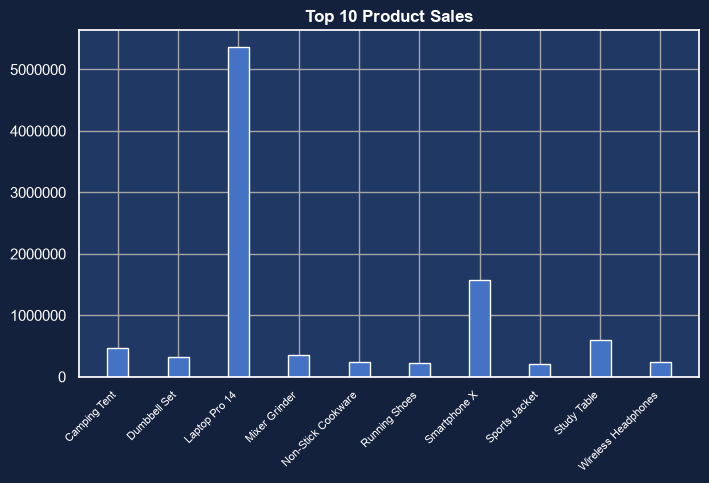

In [225]:
def top10_chart(ax):
    ax.bar(top10.index, top10.values, color=BLUE, width=0.35)
    ax.set_title('Top 10 Product Sales', fontweight='bold')
    ax.yaxis.set_major_formatter(plain)
    plt.setp(ax.get_xticklabels(), rotation=45, ha='right', fontsize=8)

fig, ax = plt.subplots(figsize=(8, 4.5), facecolor=NAVY)
top10_chart(ax)
plt.show()

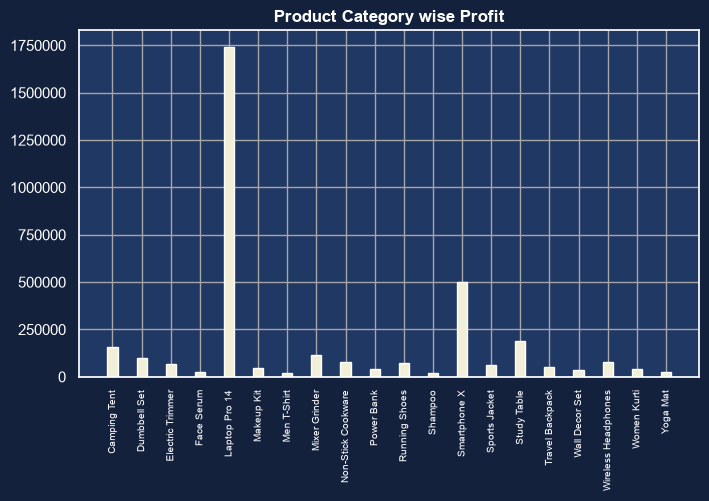

In [226]:
def profit_chart(ax):
    ax.bar(prod_profit.index, prod_profit.values, color=CREAM, width=0.35)
    ax.set_title('Product Category wise Profit', fontweight='bold')
    ax.yaxis.set_major_formatter(plain)
    plt.setp(ax.get_xticklabels(), rotation=90, fontsize=7)

fig, ax = plt.subplots(figsize=(8, 4.5), facecolor=NAVY)
profit_chart(ax)
plt.show()

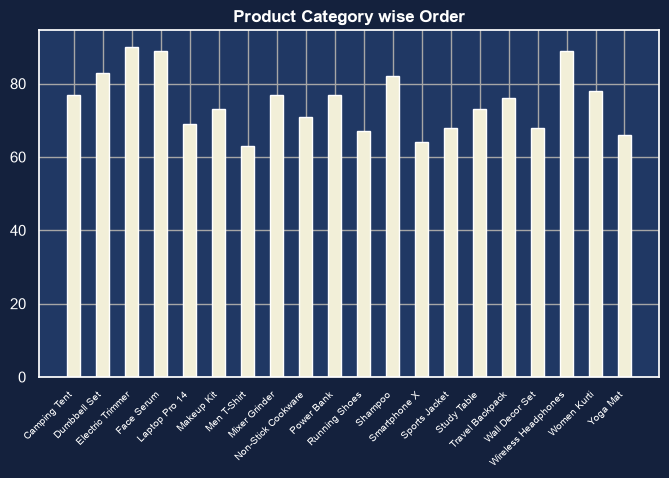

In [227]:
def order_chart(ax):
    ax.bar(prod_orders.index, prod_orders.values, color=CREAM, width=0.45)
    ax.set_title('Product Category wise Order', fontweight='bold')
    plt.setp(ax.get_xticklabels(), rotation=45, ha='right', fontsize=7)

fig, ax = plt.subplots(figsize=(8, 4.5), facecolor=NAVY)
order_chart(ax)
plt.show()

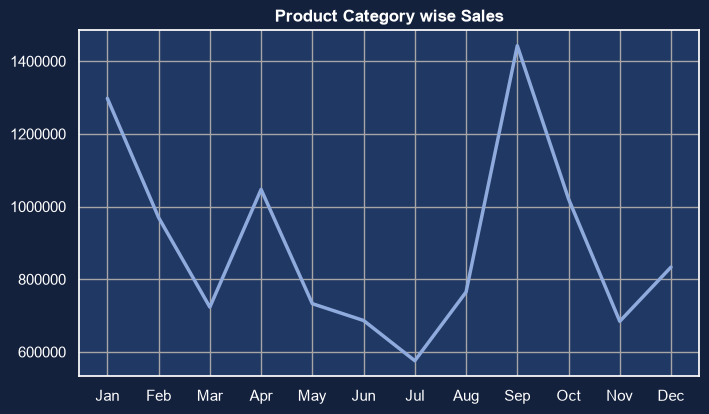

In [228]:
def sales_chart(ax):
    ax.plot(MONTHS, monthly.values, color=LIGHT_BLUE, lw=2.5)
    ax.set_title('Product Category wise Sales', fontweight='bold')
    ax.yaxis.set_major_formatter(plain)

fig, ax = plt.subplots(figsize=(8, 4.5), facecolor=NAVY)
sales_chart(ax)
plt.show()

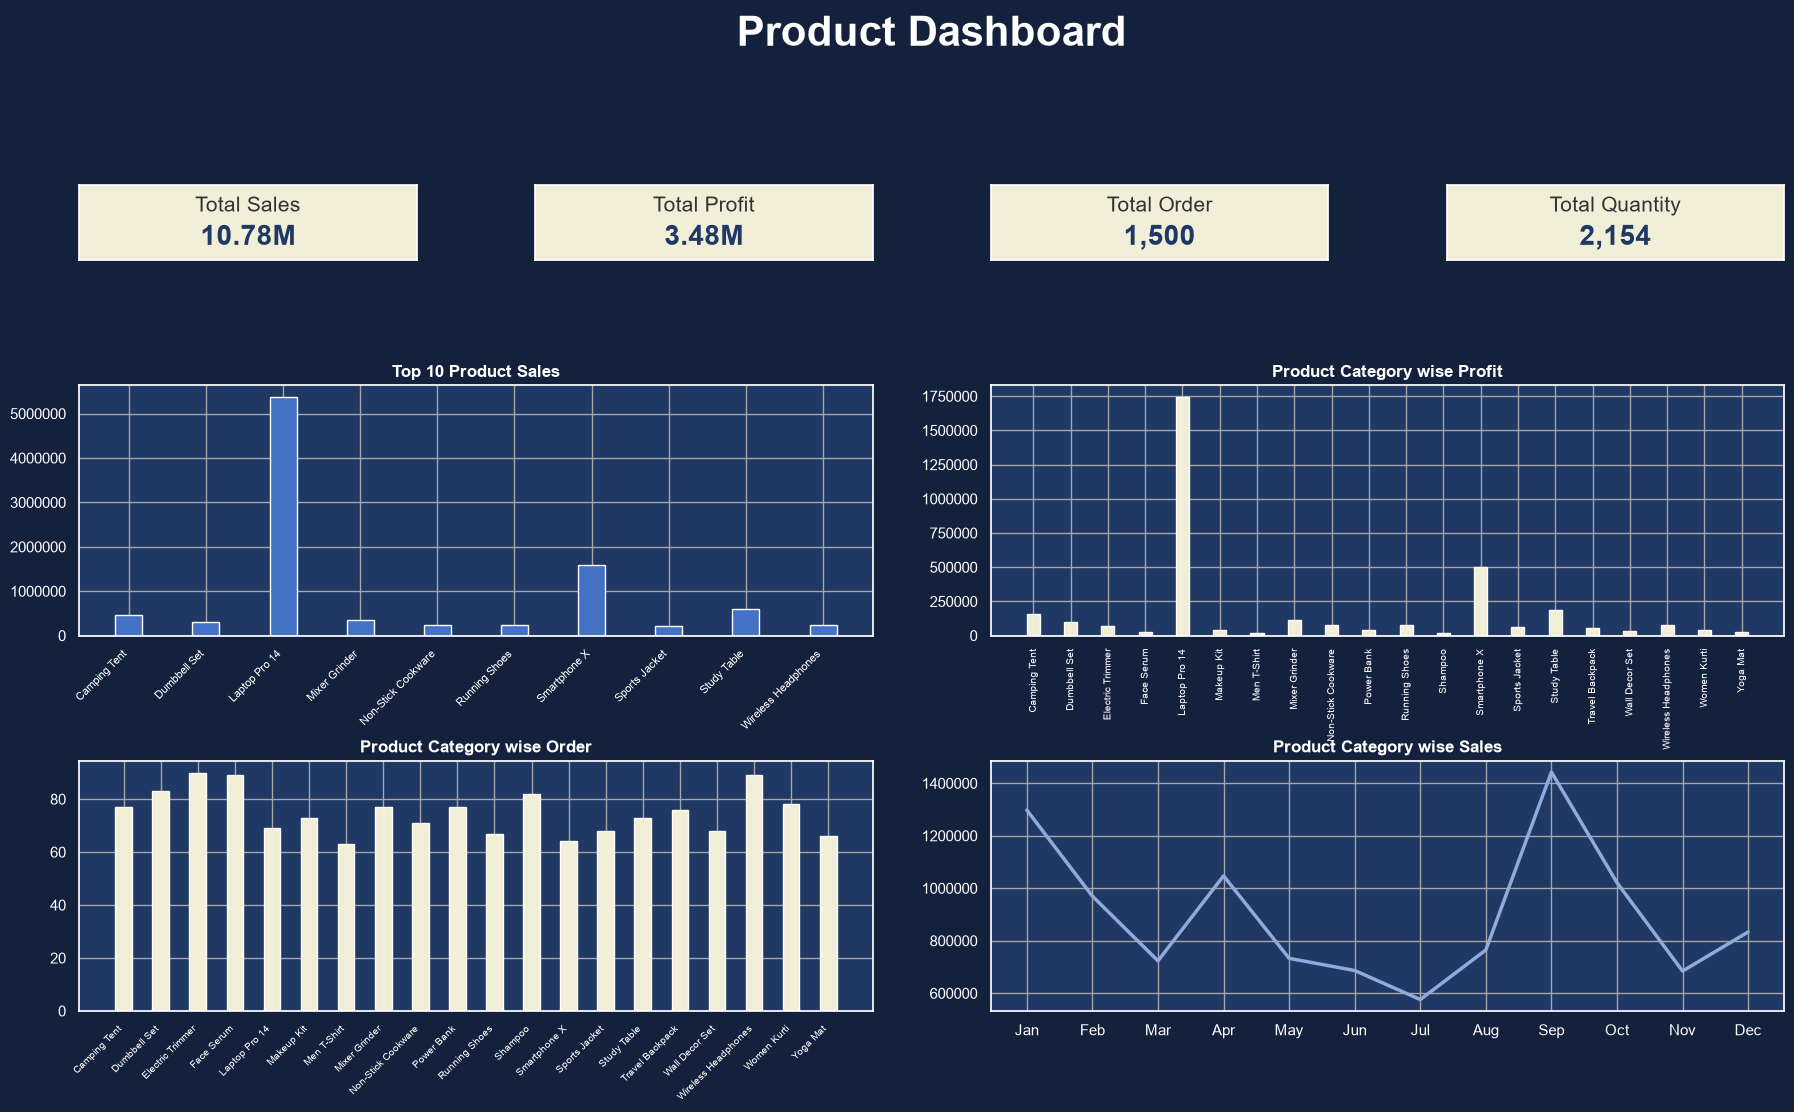

In [229]:
fig = plt.figure(figsize=(22, 13), facecolor=NAVY)
gs = fig.add_gridspec(4, 4, height_ratios=[0.6, 0.9, 3, 3], hspace=0.8, wspace=0.35)

# Title
ax = fig.add_subplot(gs[0, :]); ax.axis('off')
ax.text(0.5, 0.5, 'Product Dashboard', ha='center', va='center',
        fontsize=30, fontweight='bold', color=WHITE)

# 4 KPI cards
kpis = [('Total Sales',    f"{df['NetSales'].sum()/1e6:.2f}M"),
        ('Total Profit',   f"{df['Profit'].sum()/1e6:.2f}M"),
        ('Total Order',    f"{df['OrderID'].nunique():,}"),
        ('Total Quantity', f"{df[QTY_COL].sum():,}")]
for i, (label, val) in enumerate(kpis):
    ax = fig.add_subplot(gs[1, i])
    ax.set_facecolor(CREAM); ax.set_xticks([]); ax.set_yticks([])
    ax.grid(False)
    ax.text(0.5, 0.72, label, ha='center', va='center', fontsize=15, color='#333333')
    ax.text(0.5, 0.30, val, ha='center', va='center', fontsize=20,
            fontweight='bold', color=DARK_BLUE)

# 4 charts, 2x2
top10_chart(fig.add_subplot(gs[2, 0:2]))
profit_chart(fig.add_subplot(gs[2, 2:4]))
order_chart(fig.add_subplot(gs[3, 0:2]))
sales_chart(fig.add_subplot(gs[3, 2:4]))

fig.savefig('Product_Dashboard.png', dpi=200, facecolor=NAVY, bbox_inches='tight')
plt.show()

In [230]:
print(df.columns.tolist())

['OrderID', 'OrderDate', 'CustomerID', 'CustomerSegment', 'Gender', 'Age', 'City', 'State', 'ProductID', 'ProductName', 'Category', 'Subcategory', 'Quantity', 'UnitPrice', 'DiscountPct', 'GrossSales', 'DiscountAmount', 'NetSales', 'Cost', 'Profit', 'PaymentMethod', 'OrderStatus', 'ExpectedDeliveryDate', 'DeliveryDate', 'DeliveryDays', 'ReturnedFlag', 'CancelledFlag', 'ReturnReason', 'RefundAmount', 'MarketingChannel', 'Campaign', 'Rating', 'DeliveryDelayDays', 'OnTimeDeliveryFlag', 'Month']


In [231]:
from matplotlib.ticker import FuncFormatter

STATUS_COL = 'OrderStatus'     # अपने column नाम से बदलो
DELIV_COL  = 'DeliveryDays'    # अपने column नाम से बदलो
CREAM = '#F2EFD8'
MONTHS = ['Jan','Feb','Mar','Apr','May','Jun','Jul','Aug','Sep','Oct','Nov','Dec']
plain = FuncFormatter(lambda x, p: f'{int(x)}')

print(df[STATUS_COL].unique())   # status की values देख लो

df['Month'] = df['OrderDate'].dt.month
df['Year']  = df['OrderDate'].dt.year

status_cnt  = df.groupby(STATUS_COL)['OrderID'].nunique()
order_month = df.groupby('Month')['OrderID'].nunique().reindex(range(1, 13))
deliv_year  = df.groupby('Year')[DELIV_COL].sum()
avg_deliv   = df.groupby('Month')[DELIV_COL].mean().reindex(range(1, 13))

STATUS_COLORS = [ORANGE, BLUE, LIGHT_BLUE, '#FFC000']

<ArrowStringArray>
['Shipped', 'Delivered', 'Returned', 'Cancelled']
Length: 4, dtype: str


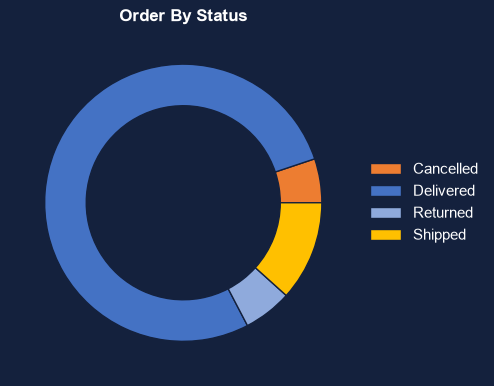

In [232]:
def status_chart(ax):
    ax.pie(status_cnt.values, colors=STATUS_COLORS[:len(status_cnt)],
           wedgeprops=dict(width=0.3, edgecolor=NAVY))
    ax.legend(status_cnt.index, loc='center left', bbox_to_anchor=(1, 0.5),
              frameon=False, labelcolor=WHITE)
    ax.set_title('Order By Status', fontweight='bold')

fig, ax = plt.subplots(figsize=(8, 4.5), facecolor=NAVY)
status_chart(ax)
plt.show()

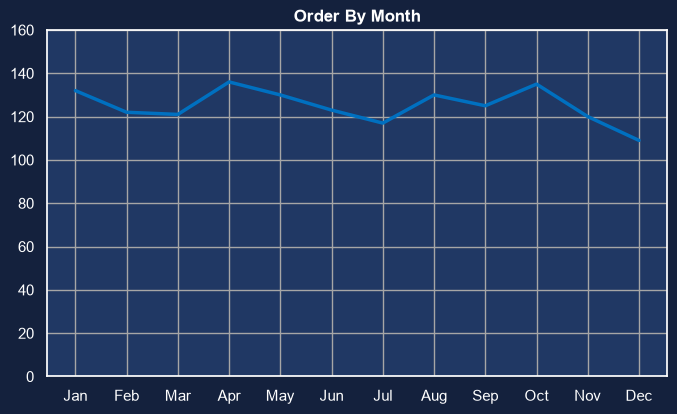

In [233]:
def order_month_chart(ax):
    ax.plot(MONTHS, order_month.values, color='#0070C0', lw=2.5)
    ax.set_title('Order By Month', fontweight='bold')
    ax.set_ylim(0, 160)

fig, ax = plt.subplots(figsize=(8, 4.5), facecolor=NAVY)
order_month_chart(ax)
plt.show()

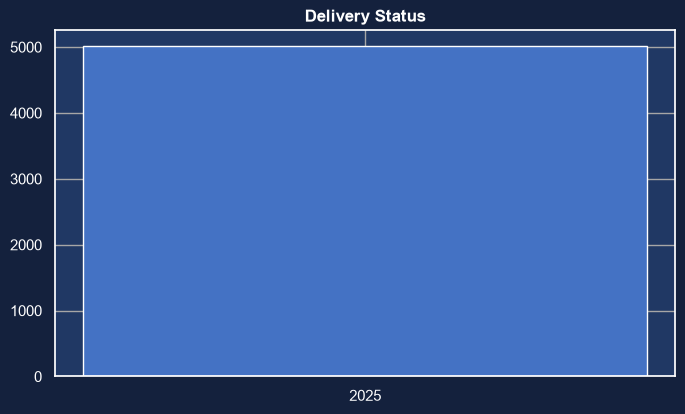

In [234]:
def deliv_status_chart(ax):
    ax.bar(deliv_year.index.astype(str), deliv_year.values, color=BLUE, width=0.25)
    ax.set_title('Delivery Status', fontweight='bold')
    ax.yaxis.set_major_formatter(plain)

fig, ax = plt.subplots(figsize=(8, 4.5), facecolor=NAVY)
deliv_status_chart(ax)
plt.show()

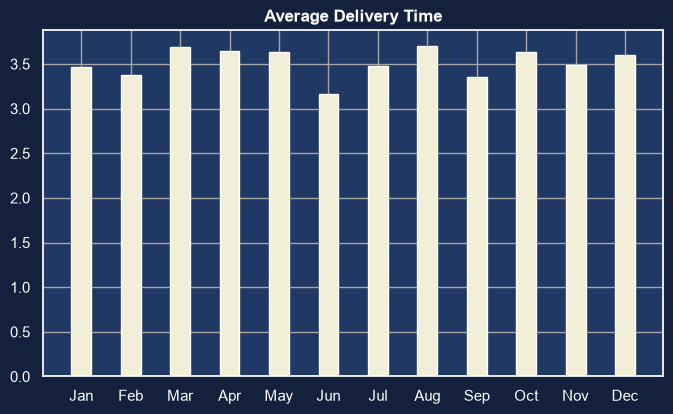

In [235]:
def avg_deliv_chart(ax):
    ax.bar(MONTHS, avg_deliv.values, color=CREAM, width=0.4)
    ax.set_title('Average Delivery Time', fontweight='bold')

fig, ax = plt.subplots(figsize=(8, 4.5), facecolor=NAVY)
avg_deliv_chart(ax)
plt.show()

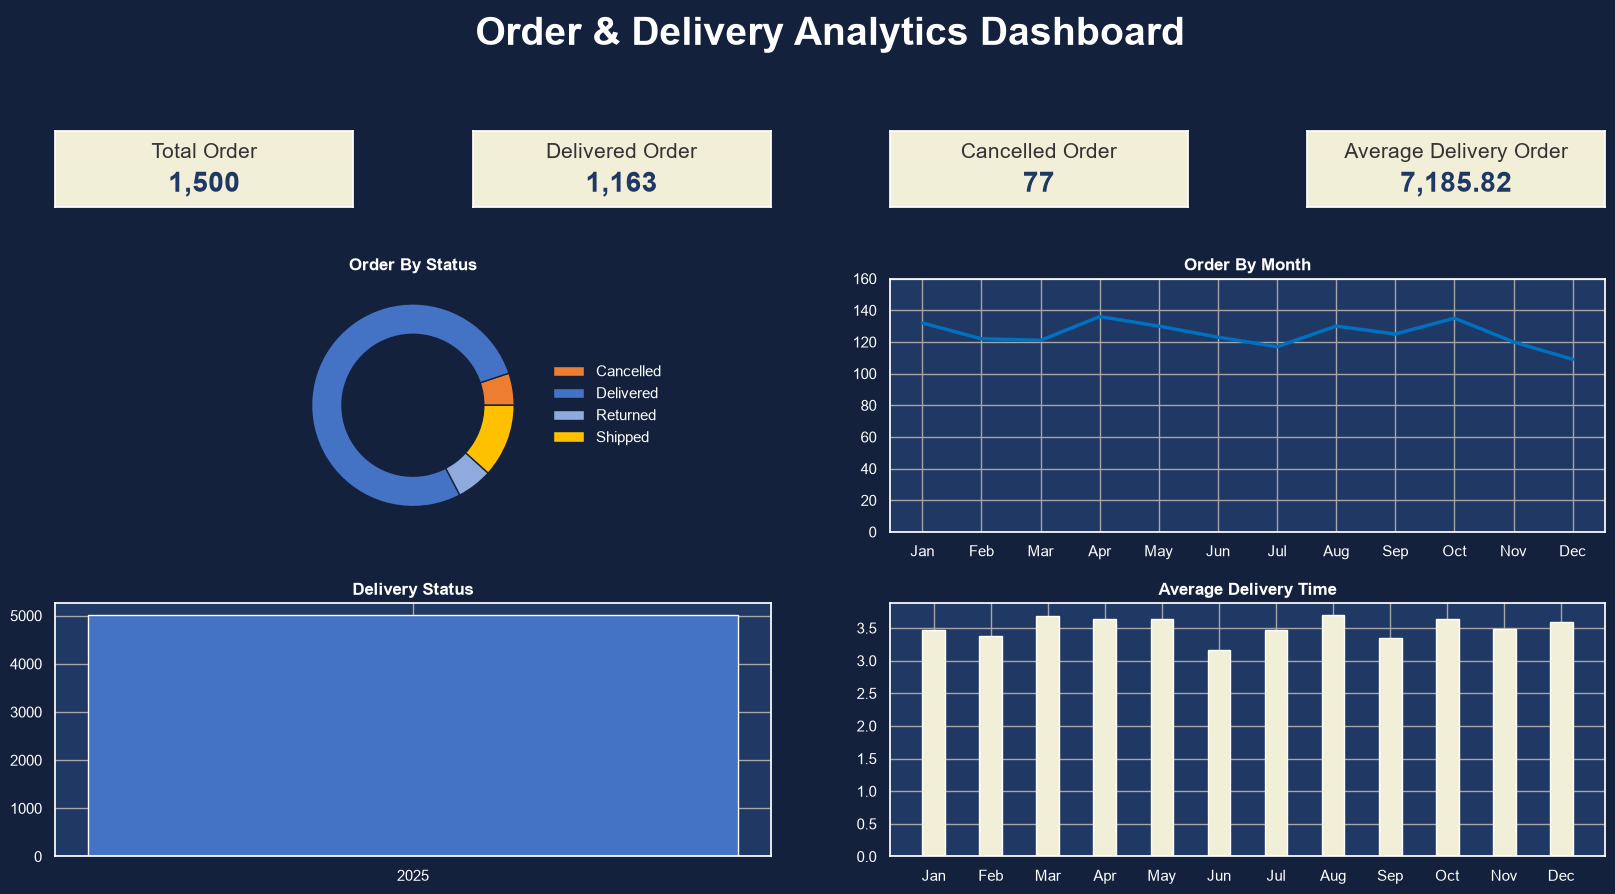

In [236]:
fig = plt.figure(figsize=(20, 11), facecolor=NAVY)
gs = fig.add_gridspec(4, 4, height_ratios=[0.6, 0.9, 3, 3], hspace=0.45, wspace=0.4)

# Title
ax = fig.add_subplot(gs[0, :]); ax.axis('off')
ax.text(0.5, 0.5, 'Order & Delivery Analytics Dashboard', ha='center', va='center',
        fontsize=28, fontweight='bold', color=WHITE)

# 4 KPI cards
orders = df['OrderID'].nunique()
delivered = df[df[STATUS_COL] == 'Delivered']['OrderID'].nunique()
cancelled = df[df[STATUS_COL] == 'Cancelled']['OrderID'].nunique()
kpis = [('Total Order', f"{orders:,}"),
        ('Delivered Order', f"{delivered:,}"),
        ('Cancelled Order', f"{cancelled:,}"),
        ('Average Delivery Order', f"{df['NetSales'].sum()/orders:,.2f}")]
for i, (label, val) in enumerate(kpis):
    ax = fig.add_subplot(gs[1, i])
    ax.set_facecolor(CREAM); ax.set_xticks([]); ax.set_yticks([])
    ax.grid(False)
    ax.text(0.5, 0.72, label, ha='center', va='center', fontsize=15, color='#333333')
    ax.text(0.5, 0.30, val, ha='center', va='center', fontsize=20,
            fontweight='bold', color=DARK_BLUE)

# 4 charts, 2x2
status_chart(fig.add_subplot(gs[2, 0:2]))
order_month_chart(fig.add_subplot(gs[2, 2:4]))
deliv_status_chart(fig.add_subplot(gs[3, 0:2]))
avg_deliv_chart(fig.add_subplot(gs[3, 2:4]))

fig.savefig('Order_Delivery_Dashboard.png', dpi=200, facecolor=NAVY, bbox_inches='tight')
plt.show()

In [237]:
from matplotlib.ticker import FuncFormatter

CREAM = '#F2EFD8'
MONTHS = ['Jan','Feb','Mar','Apr','May','Jun','Jul','Aug','Sep','Oct','Nov','Dec']
plain = FuncFormatter(lambda x, p: f'{int(x)}')

GEN_COLORS = {'Female': ORANGE, 'Male': BLUE, 'Other': LIGHT_BLUE}

df['Month'] = df['OrderDate'].dt.month

order_month = df.groupby('Month')['OrderID'].nunique().reindex(range(1, 13))
sales_month = df.groupby('Month')['NetSales'].sum().reindex(range(1, 13))
seg_orders  = df.groupby('CustomerSegment')['OrderID'].nunique().sort_values(ascending=False)
gen_sales   = df.groupby('Gender')['NetSales'].sum()

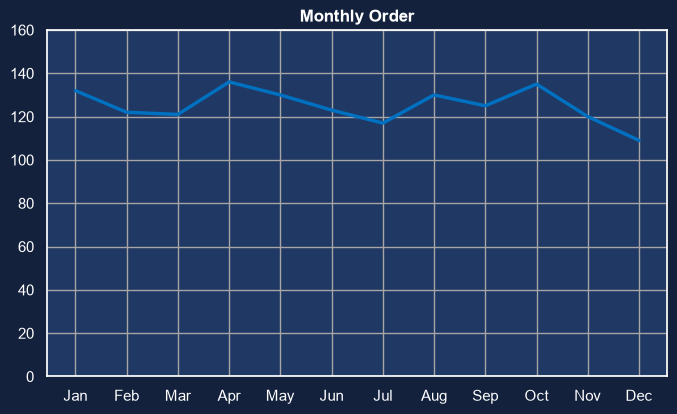

In [238]:
def monthly_order_chart(ax):
    ax.plot(MONTHS, order_month.values, color='#0070C0', lw=2.5)
    ax.set_title('Monthly Order', fontweight='bold')
    ax.set_ylim(0, 160)

fig, ax = plt.subplots(figsize=(8, 4.5), facecolor=NAVY)
monthly_order_chart(ax)
plt.show()

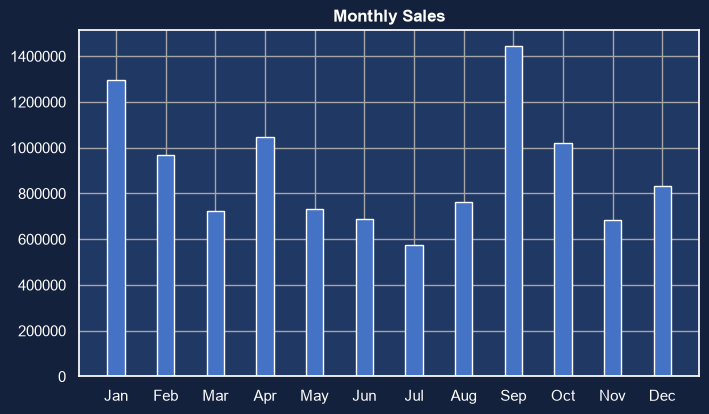

In [239]:
def monthly_sales_chart(ax):
    ax.bar(MONTHS, sales_month.values, color=BLUE, width=0.35)
    ax.set_title('Monthly Sales', fontweight='bold')
    ax.yaxis.set_major_formatter(plain)

fig, ax = plt.subplots(figsize=(8, 4.5), facecolor=NAVY)
monthly_sales_chart(ax)
plt.show()

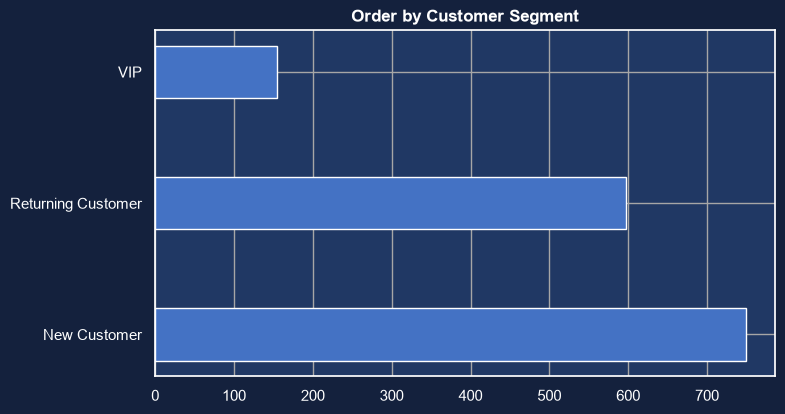

In [240]:
def seg_order_chart(ax):
    ax.barh(seg_orders.index, seg_orders.values, color=BLUE, height=0.4)
    ax.set_title('Order by Customer Segment', fontweight='bold')

fig, ax = plt.subplots(figsize=(8, 4.5), facecolor=NAVY)
seg_order_chart(ax)
plt.show()

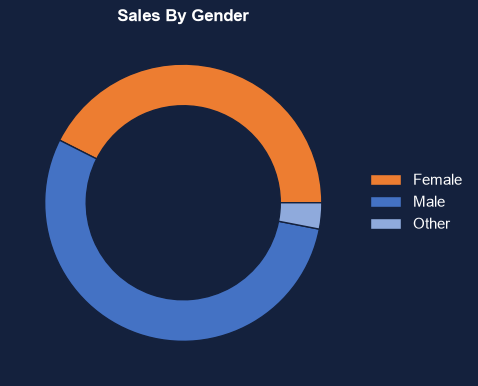

In [241]:
def gender_sales_chart(ax):
    ax.pie(gen_sales.values, colors=[GEN_COLORS[g] for g in gen_sales.index],
           wedgeprops=dict(width=0.3, edgecolor=NAVY))
    ax.legend(gen_sales.index, loc='center left', bbox_to_anchor=(1, 0.5),
              frameon=False, labelcolor=WHITE)
    ax.set_title('Sales By Gender', fontweight='bold')

fig, ax = plt.subplots(figsize=(8, 4.5), facecolor=NAVY)
gender_sales_chart(ax)
plt.show()

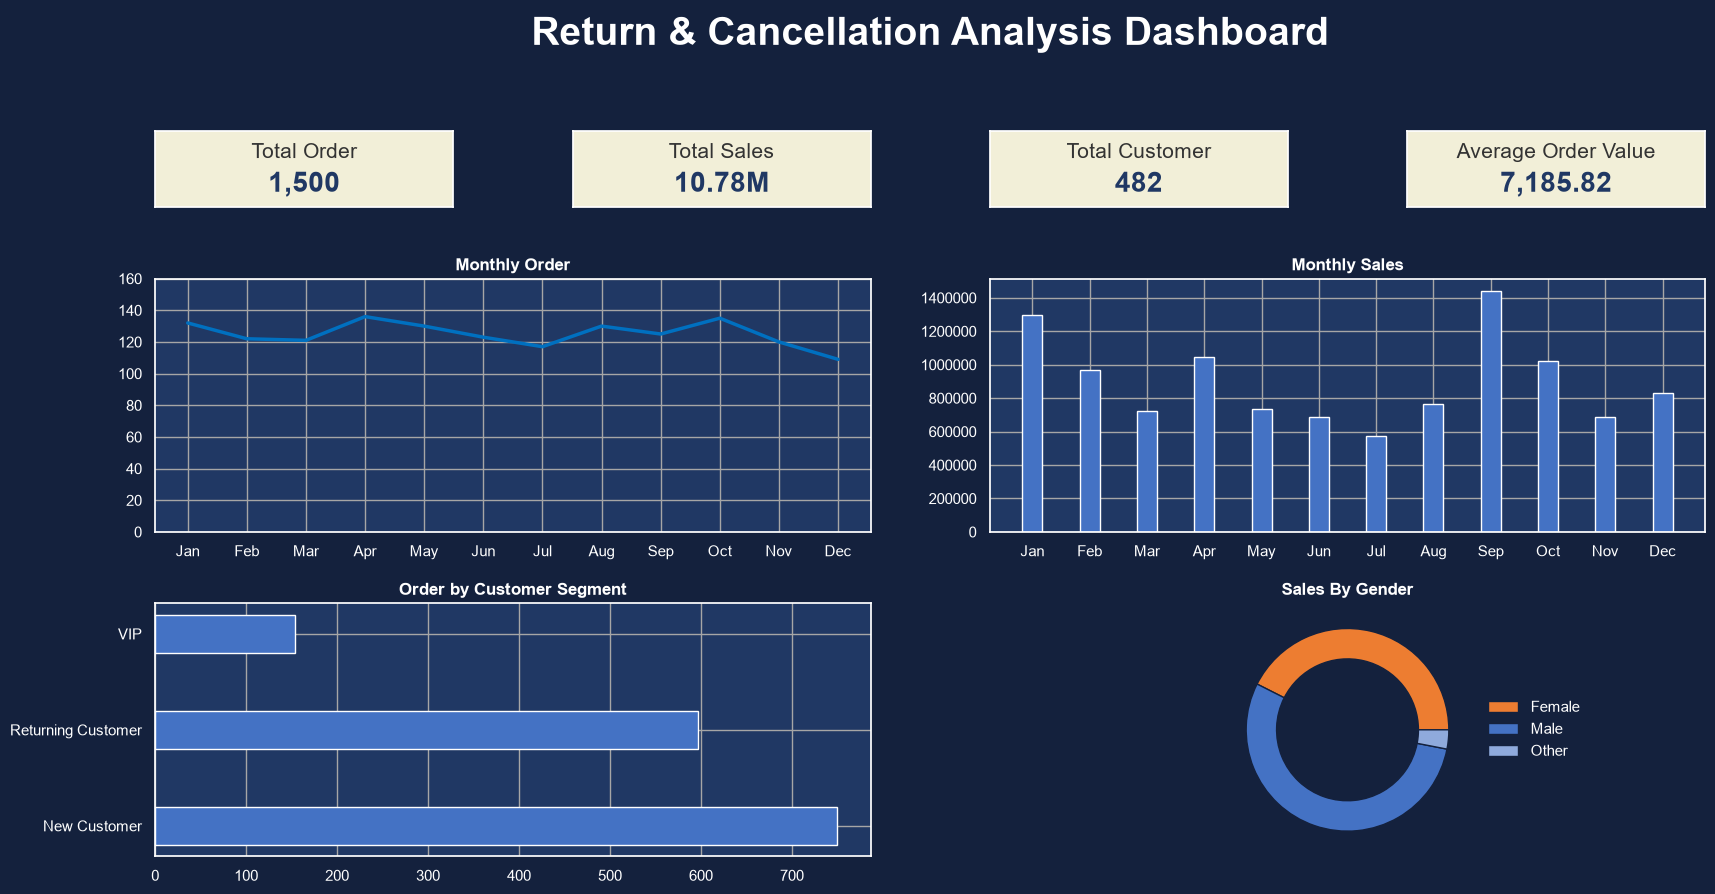

In [242]:
fig = plt.figure(figsize=(20, 11), facecolor=NAVY)
gs = fig.add_gridspec(4, 4, height_ratios=[0.6, 0.9, 3, 3], hspace=0.45, wspace=0.4)

# Title
ax = fig.add_subplot(gs[0, :]); ax.axis('off')
ax.text(0.5, 0.5, 'Return & Cancellation Analysis Dashboard', ha='center', va='center',
        fontsize=28, fontweight='bold', color=WHITE)

# 4 KPI cards
orders = df['OrderID'].nunique()
kpis = [('Total Order', f"{orders:,}"),
        ('Total Sales', f"{df['NetSales'].sum()/1e6:.2f}M"),
        ('Total Customer', f"{df['CustomerID'].nunique():,}"),
        ('Average Order Value', f"{df['NetSales'].sum()/orders:,.2f}")]
for i, (label, val) in enumerate(kpis):
    ax = fig.add_subplot(gs[1, i])
    ax.set_facecolor(CREAM); ax.set_xticks([]); ax.set_yticks([])
    ax.grid(False)
    ax.text(0.5, 0.72, label, ha='center', va='center', fontsize=15, color='#333333')
    ax.text(0.5, 0.30, val, ha='center', va='center', fontsize=20,
            fontweight='bold', color=DARK_BLUE)

# 4 charts, 2x2
monthly_order_chart(fig.add_subplot(gs[2, 0:2]))
monthly_sales_chart(fig.add_subplot(gs[2, 2:4]))
seg_order_chart(fig.add_subplot(gs[3, 0:2]))
gender_sales_chart(fig.add_subplot(gs[3, 2:4]))

fig.savefig('Return_Cancellation_Dashboard.png', dpi=200, facecolor=NAVY, bbox_inches='tight')
plt.show()

In [243]:
from matplotlib.ticker import FuncFormatter

CREAM = '#F2EFD8'
MONTHS = ['Jan','Feb','Mar','Apr','May','Jun','Jul','Aug','Sep','Oct','Nov','Dec']
plain = FuncFormatter(lambda x, p: f'{int(x)}')

df['Month'] = df['OrderDate'].dt.month

rev_month    = df.groupby('Month')['NetSales'].sum().reindex(range(1, 13))
profit_month = df.groupby('Month')['Profit'].sum().reindex(range(1, 13))
seg_rev      = df.groupby('CustomerSegment')['NetSales'].sum().sort_values(ascending=False)
seg_profit   = df.groupby('CustomerSegment')['Profit'].sum().sort_values()

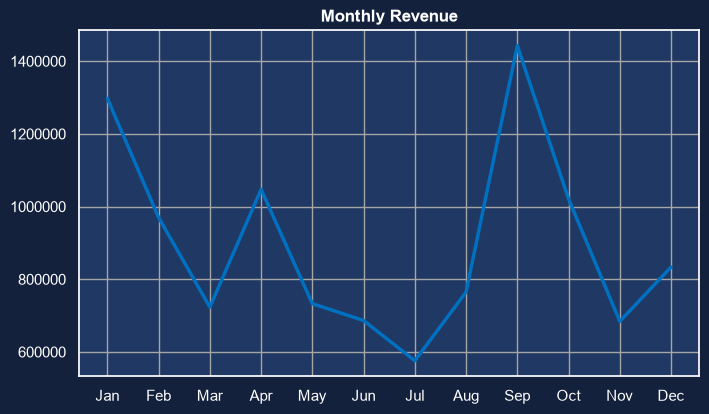

In [244]:
def monthly_rev_chart(ax):
    ax.plot(MONTHS, rev_month.values, color='#0070C0', lw=2.5)
    ax.set_title('Monthly Revenue', fontweight='bold')
    ax.yaxis.set_major_formatter(plain)

fig, ax = plt.subplots(figsize=(8, 4.5), facecolor=NAVY)
monthly_rev_chart(ax)
plt.show()

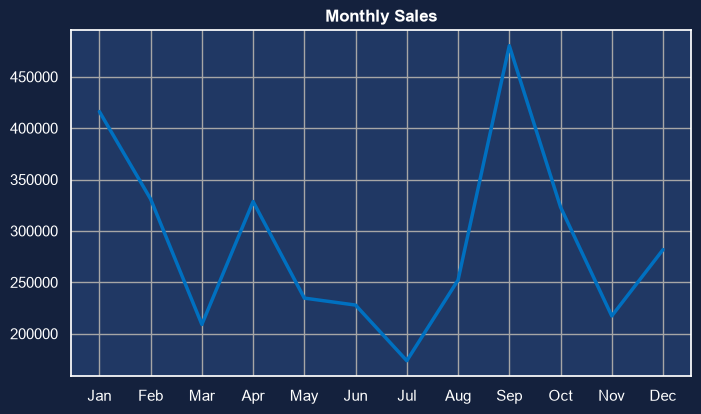

In [245]:
def monthly_sales_chart(ax):
    ax.plot(MONTHS, profit_month.values, color='#0070C0', lw=2.5)
    ax.set_title('Monthly Sales', fontweight='bold')
    ax.yaxis.set_major_formatter(plain)

fig, ax = plt.subplots(figsize=(8, 4.5), facecolor=NAVY)
monthly_sales_chart(ax)
plt.show()

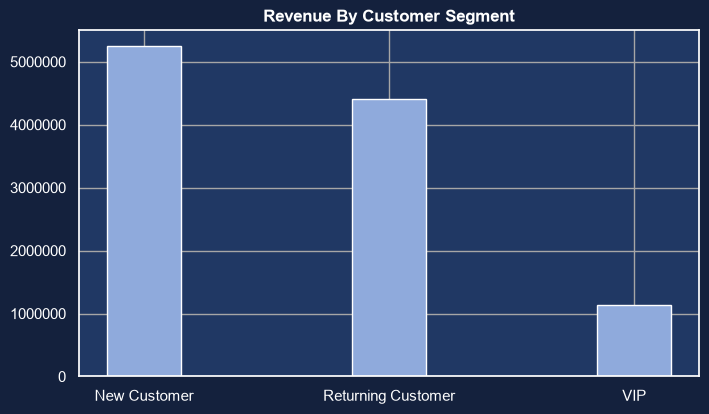

In [246]:
def seg_rev_chart(ax):
    ax.bar(seg_rev.index, seg_rev.values, color=LIGHT_BLUE, width=0.3)
    ax.set_title('Revenue By Customer Segment', fontweight='bold')
    ax.yaxis.set_major_formatter(plain)

fig, ax = plt.subplots(figsize=(8, 4.5), facecolor=NAVY)
seg_rev_chart(ax)
plt.show()

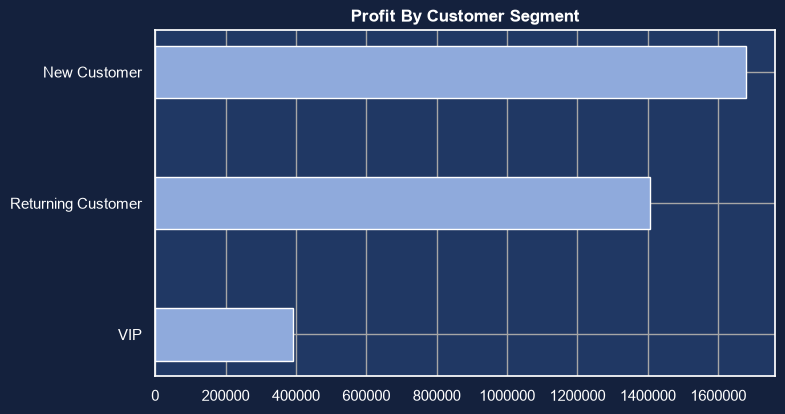

In [247]:
def seg_profit_chart(ax):
    ax.barh(seg_profit.index, seg_profit.values, color=LIGHT_BLUE, height=0.4)
    ax.set_title('Profit By Customer Segment', fontweight='bold')
    ax.xaxis.set_major_formatter(plain)

fig, ax = plt.subplots(figsize=(8, 4.5), facecolor=NAVY)
seg_profit_chart(ax)
plt.show()

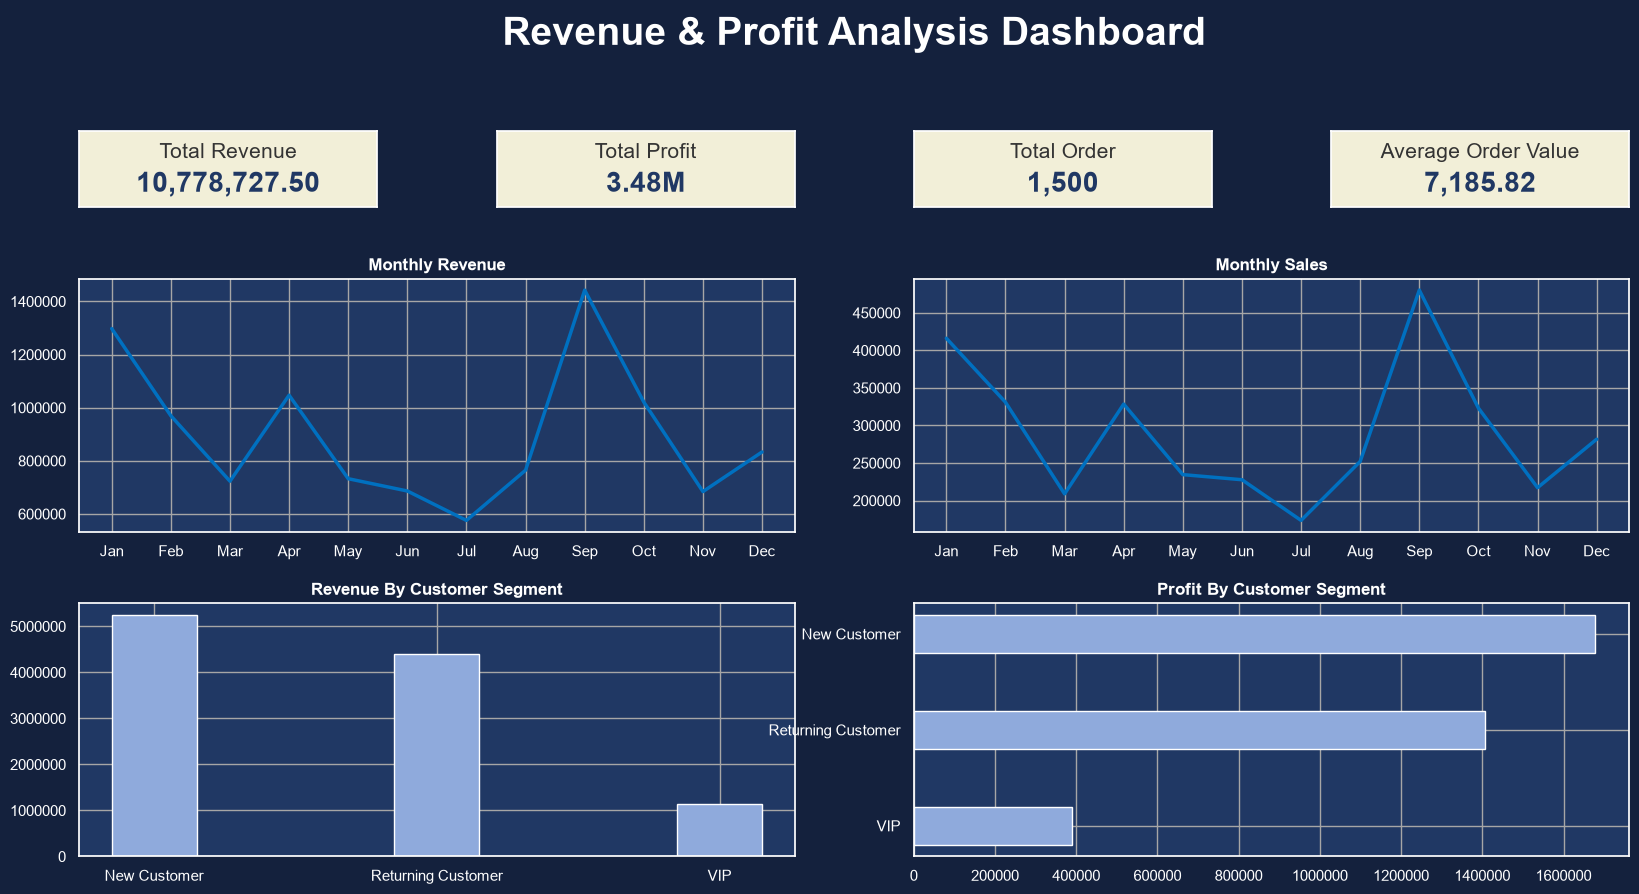

In [248]:
fig = plt.figure(figsize=(20, 11), facecolor=NAVY)
gs = fig.add_gridspec(4, 4, height_ratios=[0.6, 0.9, 3, 3], hspace=0.45, wspace=0.4)

# Title
ax = fig.add_subplot(gs[0, :]); ax.axis('off')
ax.text(0.5, 0.5, 'Revenue & Profit Analysis Dashboard', ha='center', va='center',
        fontsize=28, fontweight='bold', color=WHITE)

# 4 KPI cards
orders = df['OrderID'].nunique()
kpis = [('Total Revenue', f"{df['NetSales'].sum():,.2f}"),
        ('Total Profit', f"{df['Profit'].sum()/1e6:.2f}M"),
        ('Total Order', f"{orders:,}"),
        ('Average Order Value', f"{df['NetSales'].sum()/orders:,.2f}")]
for i, (label, val) in enumerate(kpis):
    ax = fig.add_subplot(gs[1, i])
    ax.set_facecolor(CREAM); ax.set_xticks([]); ax.set_yticks([])
    ax.grid(False)
    ax.text(0.5, 0.72, label, ha='center', va='center', fontsize=15, color='#333333')
    ax.text(0.5, 0.30, val, ha='center', va='center', fontsize=20,
            fontweight='bold', color=DARK_BLUE)

# 4 charts, 2x2
monthly_rev_chart(fig.add_subplot(gs[2, 0:2]))
monthly_sales_chart(fig.add_subplot(gs[2, 2:4]))
seg_rev_chart(fig.add_subplot(gs[3, 0:2]))
seg_profit_chart(fig.add_subplot(gs[3, 2:4]))

fig.savefig('Revenue_Profit_Dashboard.png', dpi=200, facecolor=NAVY, bbox_inches='tight')
plt.show()

In [249]:
from matplotlib.ticker import FuncFormatter

CREAM = '#F2EFD8'
MONTHS = ['Jan','Feb','Mar','Apr','May','Jun','Jul','Aug','Sep','Oct','Nov','Dec']
plain = FuncFormatter(lambda x, p: f'{int(x)}')
GEN_COLORS = {'Female': ORANGE, 'Male': BLUE, 'Other': LIGHT_BLUE}

df['Month'] = df['OrderDate'].dt.month

gen_sales   = df.groupby('Gender')['NetSales'].sum()
gen_orders  = df.groupby('Gender')['OrderID'].nunique()
seg_sales   = df.groupby('CustomerSegment')['NetSales'].sum().sort_values(ascending=False)
sales_month = df.groupby('Month')['NetSales'].sum().reindex(range(1, 13))

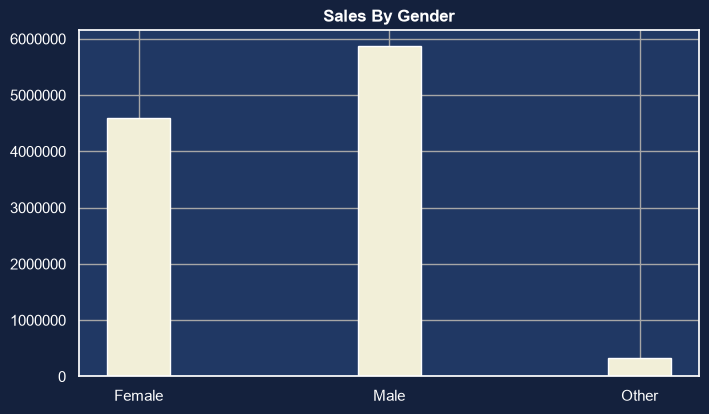

In [250]:
def gender_sales_chart(ax):
    ax.bar(gen_sales.index, gen_sales.values, color=CREAM, width=0.25)
    ax.set_title('Sales By Gender', fontweight='bold')
    ax.yaxis.set_major_formatter(plain)

fig, ax = plt.subplots(figsize=(8, 4.5), facecolor=NAVY)
gender_sales_chart(ax)
plt.show()

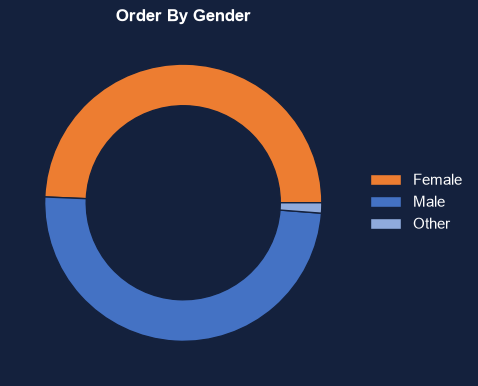

In [251]:
def gender_order_chart(ax):
    ax.pie(gen_orders.values, colors=[GEN_COLORS[g] for g in gen_orders.index],
           wedgeprops=dict(width=0.3, edgecolor=NAVY))
    ax.legend(gen_orders.index, loc='center left', bbox_to_anchor=(1, 0.5),
              frameon=False, labelcolor=WHITE)
    ax.set_title('Order By Gender', fontweight='bold')

fig, ax = plt.subplots(figsize=(8, 4.5), facecolor=NAVY)
gender_order_chart(ax)
plt.show()

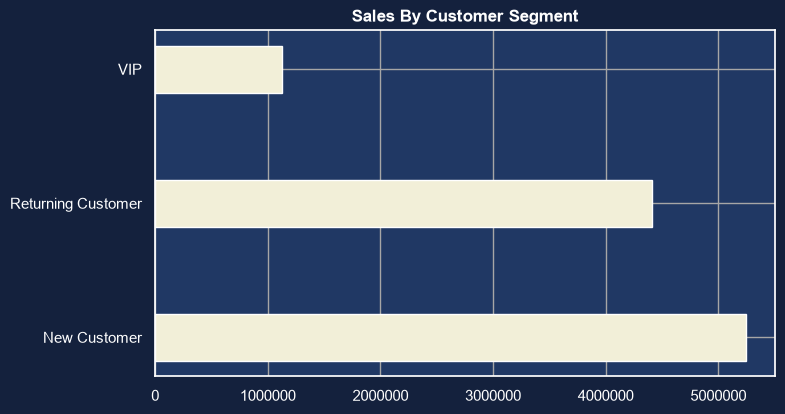

In [252]:
def seg_sales_chart(ax):
    ax.barh(seg_sales.index, seg_sales.values, color=CREAM, height=0.35)
    ax.set_title('Sales By Customer Segment', fontweight='bold')
    ax.xaxis.set_major_formatter(plain)

fig, ax = plt.subplots(figsize=(8, 4.5), facecolor=NAVY)
seg_sales_chart(ax)
plt.show()

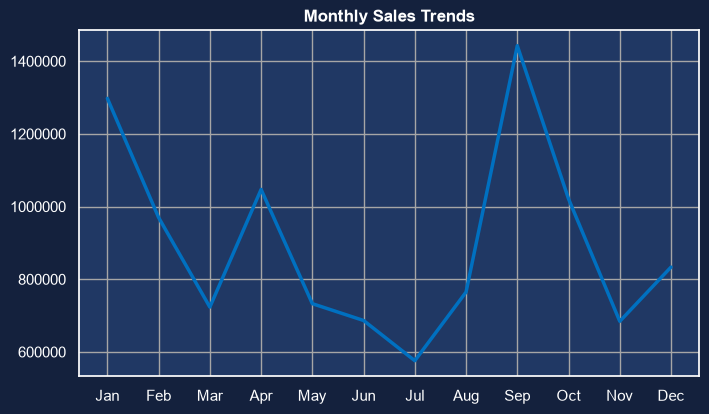

In [253]:
def monthly_trend_chart(ax):
    ax.plot(MONTHS, sales_month.values, color='#0070C0', lw=2.5)
    ax.set_title('Monthly Sales Trends', fontweight='bold')
    ax.yaxis.set_major_formatter(plain)

fig, ax = plt.subplots(figsize=(8, 4.5), facecolor=NAVY)
monthly_trend_chart(ax)
plt.show()

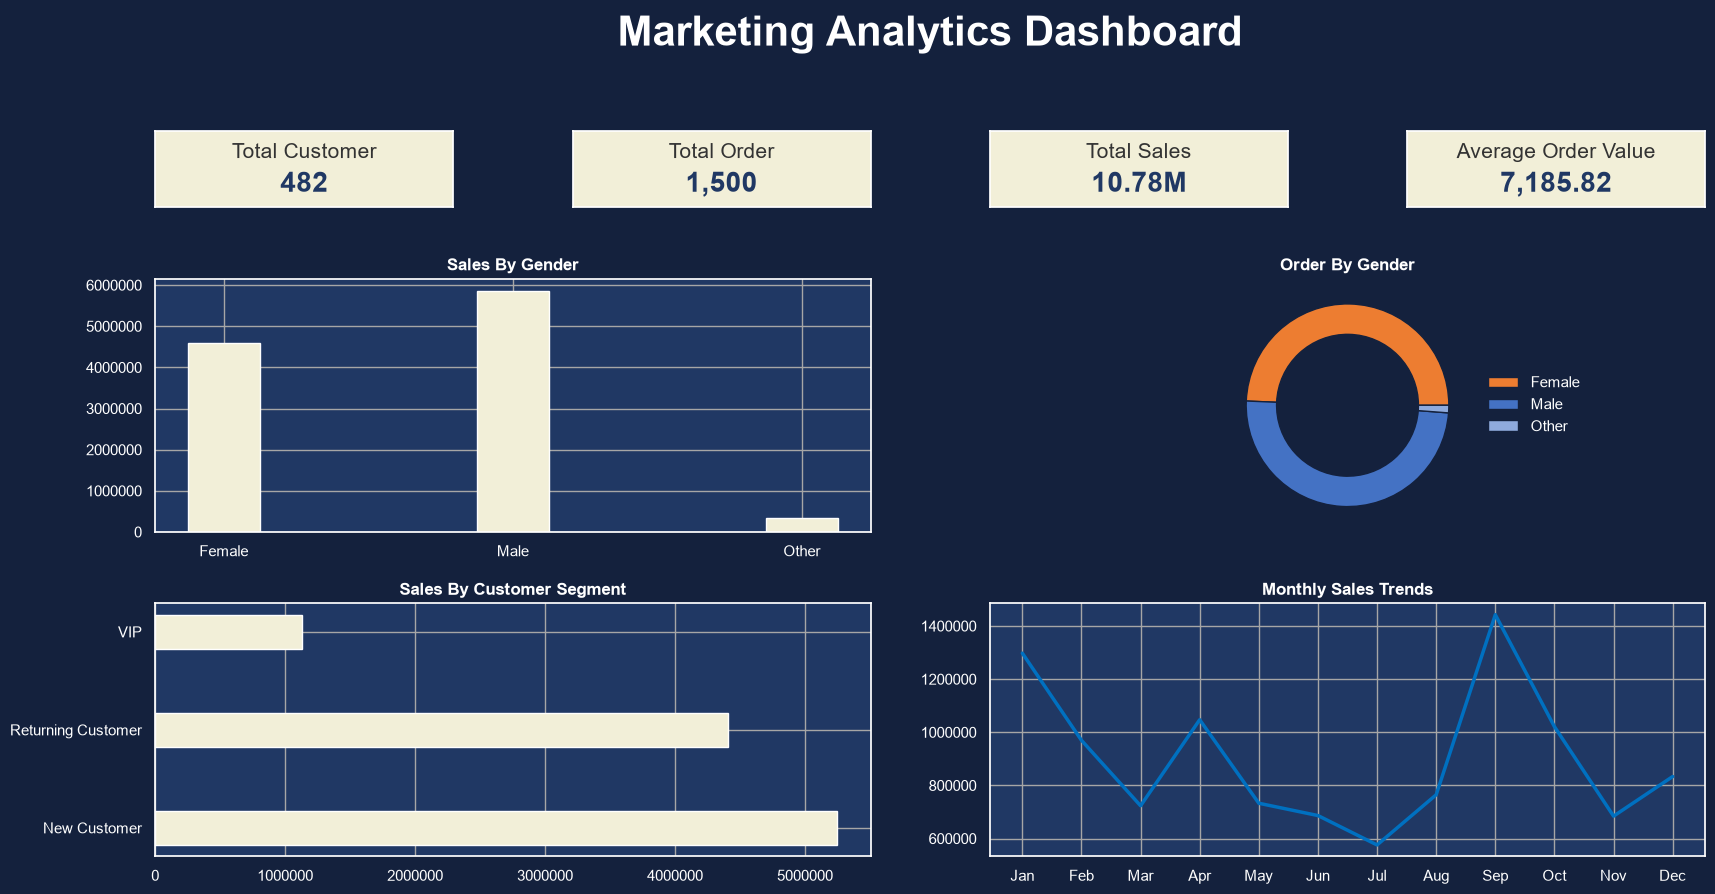

In [254]:
fig = plt.figure(figsize=(20, 11), facecolor=NAVY)
gs = fig.add_gridspec(4, 4, height_ratios=[0.6, 0.9, 3, 3], hspace=0.45, wspace=0.4)

# Title
ax = fig.add_subplot(gs[0, :]); ax.axis('off')
ax.text(0.5, 0.5, 'Marketing Analytics Dashboard', ha='center', va='center',
        fontsize=30, fontweight='bold', color=WHITE)

# 4 KPI cards
orders = df['OrderID'].nunique()
kpis = [('Total Customer', f"{df['CustomerID'].nunique():,}"),
        ('Total Order', f"{orders:,}"),
        ('Total Sales', f"{df['NetSales'].sum()/1e6:.2f}M"),
        ('Average Order Value', f"{df['NetSales'].sum()/orders:,.2f}")]
for i, (label, val) in enumerate(kpis):
    ax = fig.add_subplot(gs[1, i])
    ax.set_facecolor(CREAM); ax.set_xticks([]); ax.set_yticks([])
    ax.grid(False)
    ax.text(0.5, 0.72, label, ha='center', va='center', fontsize=15, color='#333333')
    ax.text(0.5, 0.30, val, ha='center', va='center', fontsize=20,
            fontweight='bold', color=DARK_BLUE)

# 4 charts, 2x2
gender_sales_chart(fig.add_subplot(gs[2, 0:2]))
gender_order_chart(fig.add_subplot(gs[2, 2:4]))
seg_sales_chart(fig.add_subplot(gs[3, 0:2]))
monthly_trend_chart(fig.add_subplot(gs[3, 2:4]))

fig.savefig('Marketing_Dashboard.png', dpi=200, facecolor=NAVY, bbox_inches='tight')
plt.show()

In [255]:
from matplotlib.ticker import FuncFormatter

CREAM = '#F2EFD8'
plain = FuncFormatter(lambda x, p: f'{int(x)}')
GEN_COLORS = {'Female': ORANGE, 'Male': BLUE, 'Other': LIGHT_BLUE}

seg_orders  = df.groupby('CustomerSegment')['OrderID'].nunique().sort_values(ascending=False)
gen_cust    = df.groupby('Gender')['CustomerID'].nunique()
cust_orders = df.groupby('CustomerID')['OrderID'].nunique()
top_cust    = cust_orders[cust_orders >= 7].sort_index()
seg_sales   = df.groupby('CustomerSegment')['NetSales'].sum().sort_values(ascending=False)

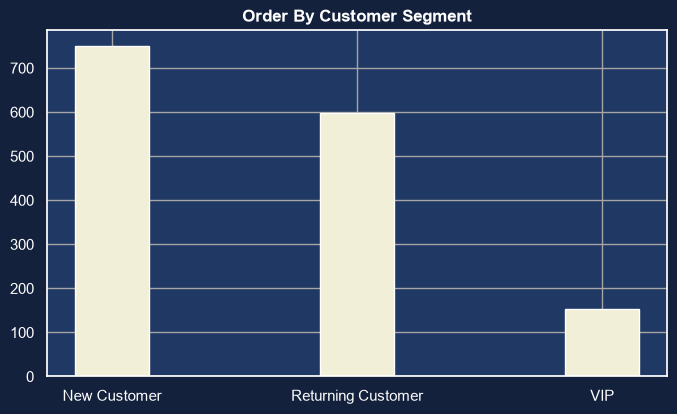

In [256]:
def seg_order_chart(ax):
    ax.bar(seg_orders.index, seg_orders.values, color=CREAM, width=0.3)
    ax.set_title('Order By Customer Segment', fontweight='bold')

fig, ax = plt.subplots(figsize=(8, 4.5), facecolor=NAVY)
seg_order_chart(ax)
plt.show()

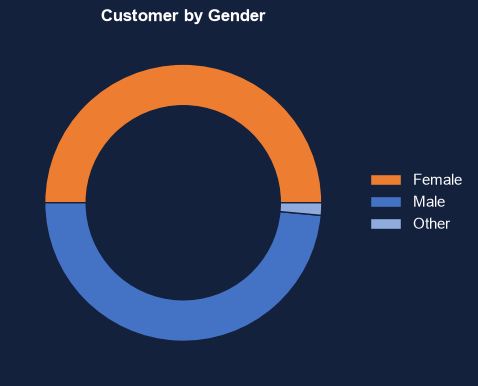

In [257]:
def gender_cust_chart(ax):
    ax.pie(gen_cust.values, colors=[GEN_COLORS[g] for g in gen_cust.index],
           wedgeprops=dict(width=0.3, edgecolor=NAVY))
    ax.legend(gen_cust.index, loc='center left', bbox_to_anchor=(1, 0.5),
              frameon=False, labelcolor=WHITE)
    ax.set_title('Customer by Gender', fontweight='bold')

fig, ax = plt.subplots(figsize=(8, 4.5), facecolor=NAVY)
gender_cust_chart(ax)
plt.show()

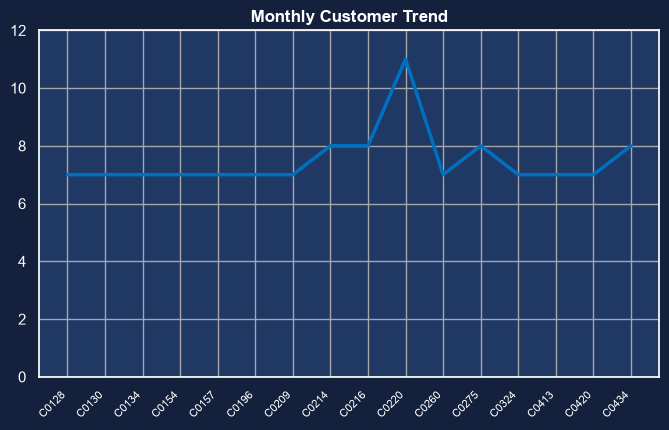

In [258]:
def cust_trend_chart(ax):
    ax.plot(top_cust.index, top_cust.values, color='#0070C0', lw=2.5)
    ax.set_title('Monthly Customer Trend', fontweight='bold')
    ax.set_ylim(0, 12)
    plt.setp(ax.get_xticklabels(), rotation=45, ha='right', fontsize=8)

fig, ax = plt.subplots(figsize=(8, 4.5), facecolor=NAVY)
cust_trend_chart(ax)
plt.show()

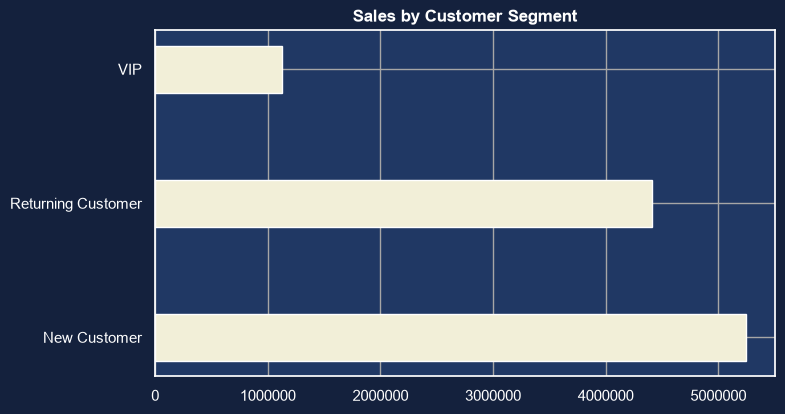

In [259]:
def seg_sales_chart(ax):
    ax.barh(seg_sales.index, seg_sales.values, color=CREAM, height=0.35)
    ax.set_title('Sales by Customer Segment', fontweight='bold')
    ax.xaxis.set_major_formatter(plain)

fig, ax = plt.subplots(figsize=(8, 4.5), facecolor=NAVY)
seg_sales_chart(ax)
plt.show()

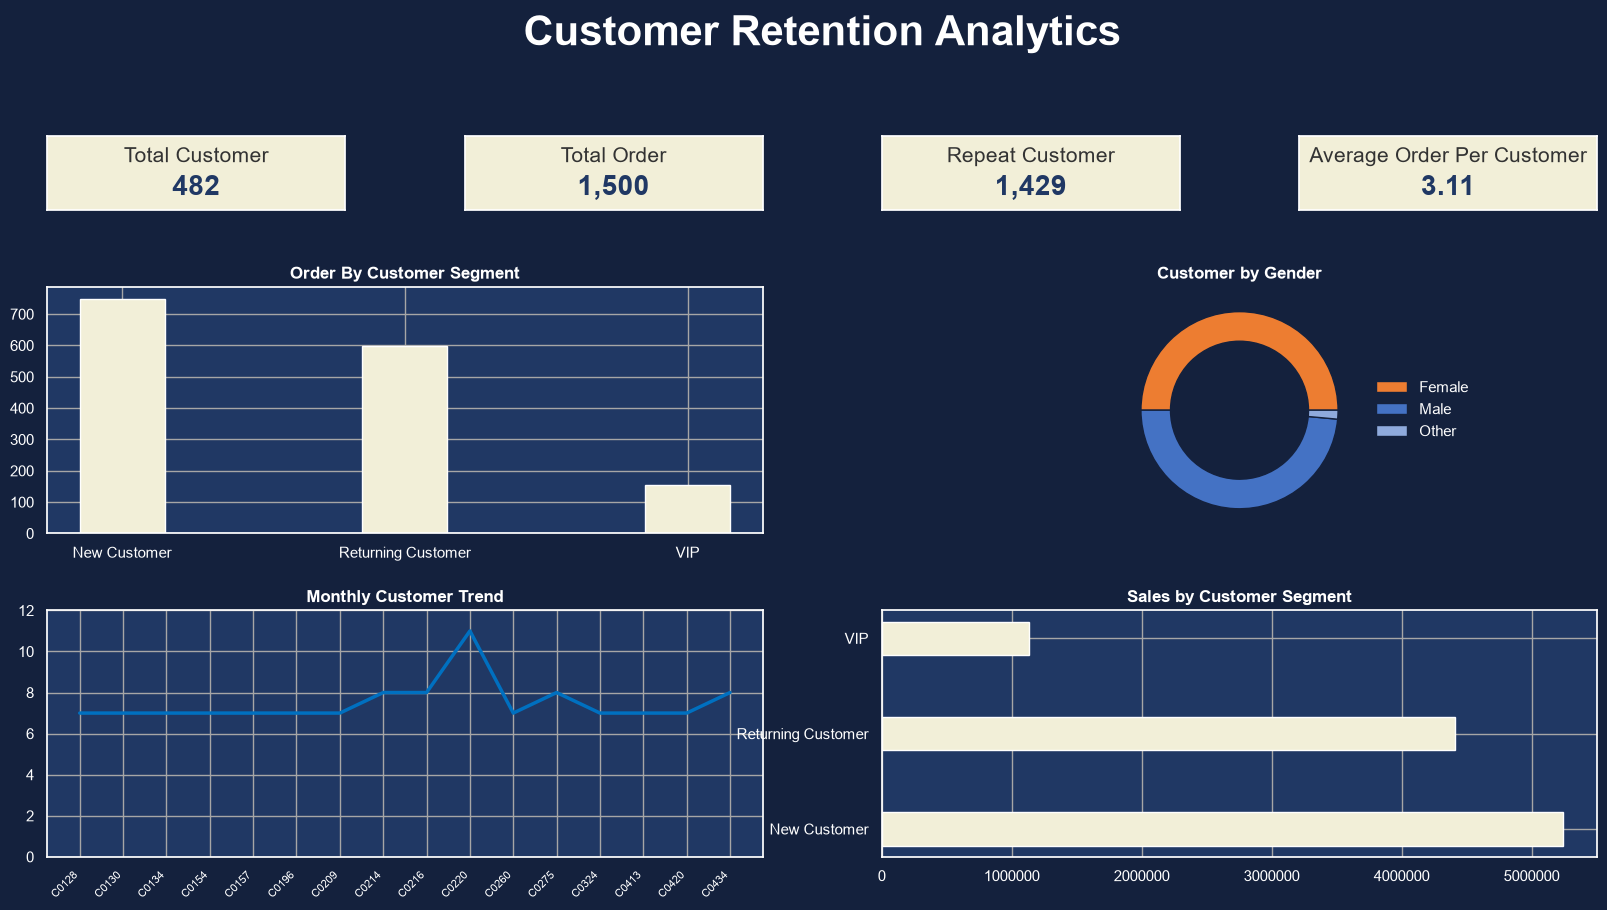

In [260]:
fig = plt.figure(figsize=(20, 11), facecolor=NAVY)
gs = fig.add_gridspec(4, 4, height_ratios=[0.6, 0.9, 3, 3], hspace=0.5, wspace=0.4)

# Title
ax = fig.add_subplot(gs[0, :]); ax.axis('off')
ax.text(0.5, 0.5, 'Customer Retention Analytics', ha='center', va='center',
        fontsize=30, fontweight='bold', color=WHITE)

# 4 KPI cards
customers = df['CustomerID'].nunique()
orders    = df['OrderID'].nunique()
repeat    = cust_orders[cust_orders > 1].sum()
kpis = [('Total Customer', f"{customers:,}"),
        ('Total Order', f"{orders:,}"),
        ('Repeat Customer', f"{repeat:,}"),
        ('Average Order Per Customer', f"{orders/customers:.2f}")]
for i, (label, val) in enumerate(kpis):
    ax = fig.add_subplot(gs[1, i])
    ax.set_facecolor(CREAM); ax.set_xticks([]); ax.set_yticks([])
    ax.grid(False)
    ax.text(0.5, 0.72, label, ha='center', va='center', fontsize=15, color='#333333')
    ax.text(0.5, 0.30, val, ha='center', va='center', fontsize=20,
            fontweight='bold', color=DARK_BLUE)

# 4 charts, 2x2
seg_order_chart(fig.add_subplot(gs[2, 0:2]))
gender_cust_chart(fig.add_subplot(gs[2, 2:4]))
cust_trend_chart(fig.add_subplot(gs[3, 0:2]))
seg_sales_chart(fig.add_subplot(gs[3, 2:4]))

fig.savefig('Customer_Retention_Dashboard.png', dpi=200, facecolor=NAVY, bbox_inches='tight')
plt.show()

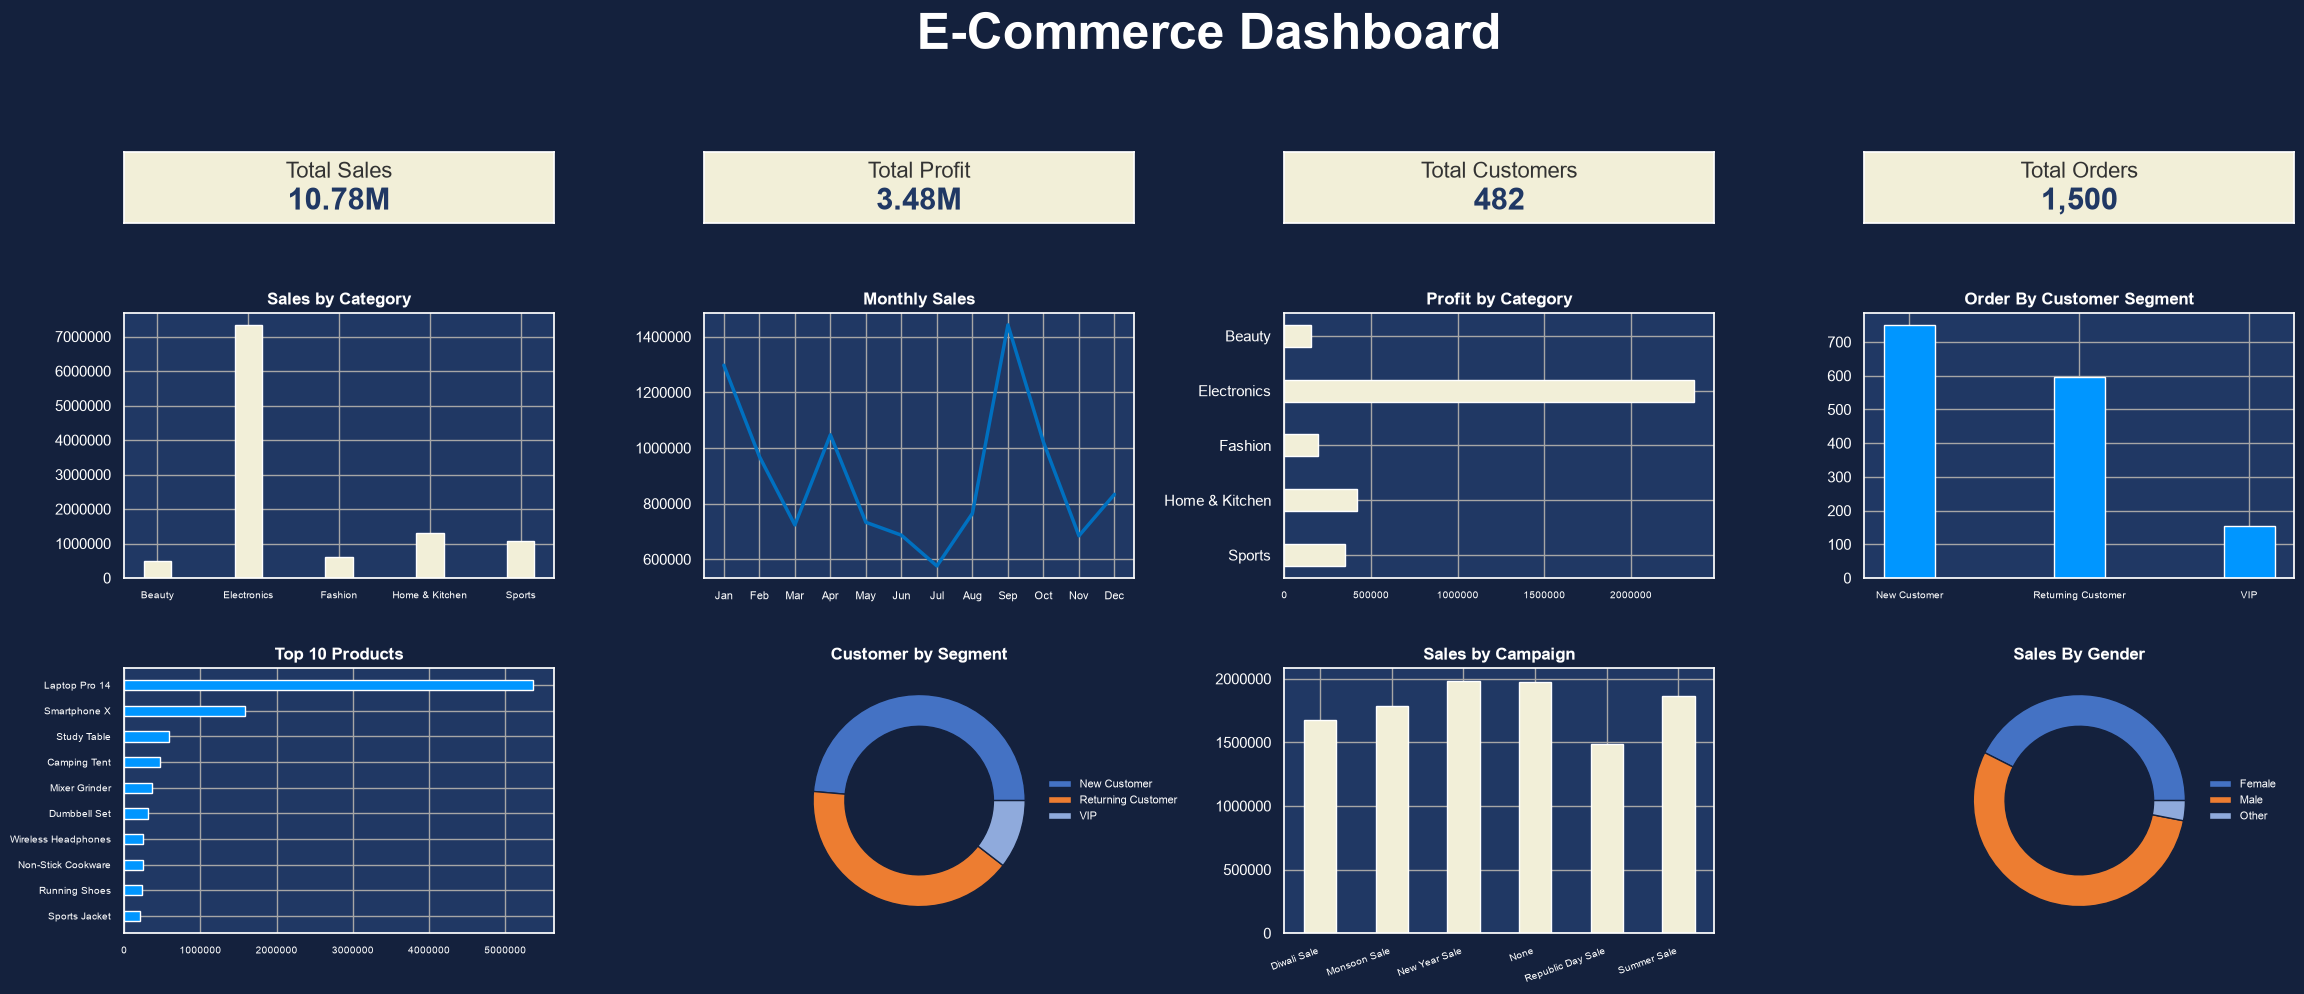

In [261]:
from matplotlib.ticker import FuncFormatter

CAT_COL  = 'Category'
PROD_COL = 'ProductName'
CAMP_COL = 'Campaign'        # अपने column नाम से बदलो

CREAM  = '#F2EFD8'
MONTHS = ['Jan','Feb','Mar','Apr','May','Jun','Jul','Aug','Sep','Oct','Nov','Dec']
plain  = FuncFormatter(lambda x, p: f'{int(x)}')
SEG_COLORS = {'New Customer': BLUE, 'Returning Customer': ORANGE, 'VIP': LIGHT_BLUE}
GEN_COLORS = {'Female': BLUE, 'Male': ORANGE, 'Other': LIGHT_BLUE}

# ---------- Data ----------
df['Month'] = df['OrderDate'].dt.month
df[CAMP_COL] = df[CAMP_COL].fillna('None')

cat_sales   = df.groupby(CAT_COL)['NetSales'].sum().sort_index()
cat_profit  = df.groupby(CAT_COL)['Profit'].sum().sort_index(ascending=False)
sales_month = df.groupby('Month')['NetSales'].sum().reindex(range(1, 13))
seg_orders  = df.groupby('CustomerSegment')['OrderID'].nunique().sort_values(ascending=False)
seg_sales   = df.groupby('CustomerSegment')['NetSales'].sum()
top10       = df.groupby(PROD_COL)['NetSales'].sum().nlargest(10).sort_values()
camp_sales  = df.groupby(CAMP_COL)['NetSales'].sum()
gen_sales   = df.groupby('Gender')['NetSales'].sum()

# ---------- Dashboard ----------
fig = plt.figure(figsize=(28, 12), facecolor=NAVY)
gs = fig.add_gridspec(4, 4, height_ratios=[0.6, 0.8, 3, 3], hspace=0.55, wspace=0.35)

# Title
ax = fig.add_subplot(gs[0, :]); ax.axis('off')
ax.text(0.5, 0.5, 'E-Commerce Dashboard', ha='center', va='center',
        fontsize=36, fontweight='bold', color=WHITE)

# KPI cards
orders = df['OrderID'].nunique()
kpis = [('Total Sales',     f"{df['NetSales'].sum()/1e6:.2f}M"),
        ('Total Profit',    f"{df['Profit'].sum()/1e6:.2f}M"),
        ('Total Customers', f"{df['CustomerID'].nunique():,}"),
        ('Total Orders',    f"{orders:,}")]
for i, (label, val) in enumerate(kpis):
    ax = fig.add_subplot(gs[1, i])
    ax.set_facecolor(CREAM); ax.set_xticks([]); ax.set_yticks([]); ax.grid(False)
    ax.text(0.5, 0.72, label, ha='center', va='center', fontsize=16, color='#333333')
    ax.text(0.5, 0.30, val, ha='center', va='center', fontsize=22,
            fontweight='bold', color=DARK_BLUE)

# Row 1
ax = fig.add_subplot(gs[2, 0])
ax.bar(cat_sales.index, cat_sales.values, color=CREAM, width=0.3)
ax.set_title('Sales by Category', fontweight='bold')
ax.yaxis.set_major_formatter(plain); ax.tick_params(axis='x', labelsize=7)

ax = fig.add_subplot(gs[2, 1])
ax.plot(MONTHS, sales_month.values, color='#0070C0', lw=2.5)
ax.set_title('Monthly Sales', fontweight='bold')
ax.yaxis.set_major_formatter(plain); ax.tick_params(axis='x', labelsize=8)

ax = fig.add_subplot(gs[2, 2])
ax.barh(cat_profit.index, cat_profit.values, color=CREAM, height=0.4)
ax.set_title('Profit by Category', fontweight='bold')
ax.xaxis.set_major_formatter(plain); ax.tick_params(axis='x', labelsize=7)

ax = fig.add_subplot(gs[2, 3])
ax.bar(seg_orders.index, seg_orders.values, color='#0096FF', width=0.3)
ax.set_title('Order By Customer Segment', fontweight='bold')
ax.tick_params(axis='x', labelsize=7)

# Row 2
ax = fig.add_subplot(gs[3, 0])
ax.barh(top10.index, top10.values, color='#0096FF', height=0.4)
ax.set_title('Top 10 Products', fontweight='bold')
ax.xaxis.set_major_formatter(plain)
ax.tick_params(axis='y', labelsize=7); ax.tick_params(axis='x', labelsize=7)

ax = fig.add_subplot(gs[3, 1])
ax.pie(seg_sales.values, colors=[SEG_COLORS[s] for s in seg_sales.index],
       wedgeprops=dict(width=0.3, edgecolor=NAVY))
ax.legend(seg_sales.index, loc='center left', bbox_to_anchor=(0.95, 0.5),
          frameon=False, labelcolor=WHITE, fontsize=8)
ax.set_title('Customer by Segment', fontweight='bold')

ax = fig.add_subplot(gs[3, 2])
ax.bar(camp_sales.index, camp_sales.values, color=CREAM, width=0.45)
ax.set_title('Sales by Campaign', fontweight='bold')
ax.yaxis.set_major_formatter(plain); ax.tick_params(axis='x', labelsize=7)
plt.setp(ax.get_xticklabels(), rotation=20, ha='right')

ax = fig.add_subplot(gs[3, 3])
ax.pie(gen_sales.values, colors=[GEN_COLORS[g] for g in gen_sales.index],
       wedgeprops=dict(width=0.3, edgecolor=NAVY))
ax.legend(gen_sales.index, loc='center left', bbox_to_anchor=(0.95, 0.5),
          frameon=False, labelcolor=WHITE, fontsize=8)
ax.set_title('Sales By Gender', fontweight='bold')

fig.savefig('Final_Dashboard.png', dpi=200, facecolor=NAVY, bbox_inches='tight')
plt.show()